# Loading the dataset

In [1]:
from fall_detection.analysis.session_parquet import load_parquet_session

from pathlib import Path
import sys
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm, Normalize, SymLogNorm
from matplotlib.ticker import MaxNLocator
from IPython.display import display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "fall_detection").is_dir()
)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))


plt.rcParams["figure.dpi"] = 70

SESSION_ID = "20261104T081805521126Z"

session = load_parquet_session(
    PROJECT_ROOT / "data" / "raw" / "sessions" / SESSION_ID,
    PROJECT_ROOT / "data" / "interim" / "parquet" / SESSION_ID,
    progress=print,
)
attempts = session.attempts
phases = session.phases
# Session summaries need metadata only; load I/Q for individual analyses below.
PACKET_COLUMNS = [
    "session_id", "attempt_key", "receiver_id", "status", "inclusion", "phase",
    "is_sensing", "capture_time_ns", "attempt_started_monotonic_ns",
    "attempt_ended_monotonic_ns", "driver_valid",
]
packets = session.read_packets(columns=PACKET_COLUMNS, arrow_backed=True)
selected_attempts = attempts.loc[
    attempts["status"].eq("accepted") & attempts["inclusion"].ne("exclude")
].copy()
selected_mask = packets["status"].eq("accepted") & packets["inclusion"].ne("exclude")

def load_receiver(attempt_key: str, receiver_id: str) -> pd.DataFrame:
    return session.read_packets(filters=[
        ("attempt_key", "==", attempt_key), ("receiver_id", "==", receiver_id),
    ])

selected_action_count = int((selected_mask & packets["phase"].eq("action")).sum())
print(f"Session: {SESSION_ID} | {len(attempts)} attempts")
print(f"{len(packets):,} packets | {len(selected_attempts)} selected attempts")
print(f"{selected_action_count:,} selected action-phase packets")
print(f"Parquet directory: {session.path}")
display(packets.head())
display(phases.head())

Session: 20261104T081805521126Z | 255 attempts
1,428,868 packets | 232 selected attempts
436,115 selected action-phase packets
Parquet directory: /home/khaelano/Projects/radio-fall-detection/data/interim/parquet/20261104T081805521126Z


,session_id,attempt_key,receiver_id,status,inclusion,phase,is_sensing,capture_time_ns,attempt_started_monotonic_ns,attempt_ended_monotonic_ns,driver_valid
0,20261104T081805521126Z,trials/001_stand-to-walk__start_no_direction__...,rx-1,invalid,unreviewed,preparation,True,9619386793625,9619380861739,9630789180568,True
1,20261104T081805521126Z,trials/001_stand-to-walk__start_no_direction__...,rx-1,invalid,unreviewed,preparation,True,9619394795625,9619380861739,9630789180568,True
2,20261104T081805521126Z,trials/001_stand-to-walk__start_no_direction__...,rx-1,invalid,unreviewed,preparation,True,9619403793625,9619380861739,9630789180568,True
3,20261104T081805521126Z,trials/001_stand-to-walk__start_no_direction__...,rx-1,invalid,unreviewed,preparation,True,9619411793625,9619380861739,9630789180568,True
4,20261104T081805521126Z,trials/001_stand-to-walk__start_no_direction__...,rx-1,invalid,unreviewed,preparation,True,9619419800625,9619380861739,9630789180568,True


,session_id,attempt_key,trial_ordinal,attempt,scenario_id,phase,collection_phase,start_ns,end_ns,annotation_source,review_revision
0,20261104T081805521126Z,trials/001_stand-to-walk__start_no_direction__...,1,1,stand-to-walk__start_no_direction__end_front,preparation,countdown,9619385467796,9624408100120,collection_cue,0
1,20261104T081805521126Z,trials/001_stand-to-walk__start_no_direction__...,1,1,stand-to-walk__start_no_direction__end_front,action,action,9624408100120,9627857703035,collection_cue,0
2,20261104T081805521126Z,trials/001_stand-to-walk__start_no_direction__...,1,1,stand-to-walk__start_no_direction__end_front,resting,recovery,9627857703035,9630789180568,collection_cue,0
3,20261104T081805521126Z,trials/001_stand-to-walk__start_no_direction__...,1,2,stand-to-walk__start_no_direction__end_front,preparation,countdown,9725412399235,9730420561845,collection_cue,0
4,20261104T081805521126Z,trials/001_stand-to-walk__start_no_direction__...,1,2,stand-to-walk__start_no_direction__end_front,action,action,9730420561845,9735916977062,collection_cue,0


# Average sensing rate

In [2]:
rate_keys = ["session_id", "attempt_key", "receiver_id"]
rate_recordings = (
    selected_attempts[
        ["session_id", "attempt_key", "receiver_ids",
         "started_monotonic_ns", "ended_monotonic_ns"]
    ]
    .explode("receiver_ids")
    .rename(columns={"receiver_ids": "receiver_id"})
    .dropna(subset=["receiver_id"])
    .copy()
)
if rate_recordings.empty:
    raise ValueError("No selected receiver recordings. Check the loading-cell filters.")

rate_recordings["recorded_seconds"] = (
    rate_recordings["ended_monotonic_ns"]
    - rate_recordings["started_monotonic_ns"]
) / 1e9
if (
    rate_recordings["recorded_seconds"].isna().any()
    or rate_recordings["recorded_seconds"].le(0).any()
):
    raise ValueError("Sensing-rate calculation requires positive, bounded attempt durations.")

rate_packet_mask = (
    selected_mask
    & packets["is_sensing"]
    & packets["capture_time_ns"].ge(packets["attempt_started_monotonic_ns"])
    & packets["capture_time_ns"].lt(packets["attempt_ended_monotonic_ns"])
)
rate_counts = (
    packets.loc[rate_packet_mask, rate_keys + ["driver_valid"]]
    .groupby(rate_keys, observed=True)
    .agg(
        sensing_packets=("driver_valid", "size"),
        driver_valid_packets=("driver_valid", "sum"),
    )
    .reset_index()
)
sensing_rate_by_attempt = rate_recordings.merge(
    rate_counts, on=rate_keys, how="left", validate="one_to_one",
)
count_columns = ["sensing_packets", "driver_valid_packets"]
sensing_rate_by_attempt[count_columns] = (
    sensing_rate_by_attempt[count_columns].fillna(0).astype("int64")
)
sensing_rate_by_attempt["average_sensing_hz"] = (
    sensing_rate_by_attempt["sensing_packets"]
    / sensing_rate_by_attempt["recorded_seconds"]
)
sensing_rate_by_receiver = (
    sensing_rate_by_attempt.groupby("receiver_id", observed=True)
    .agg(
        attempts=("attempt_key", "size"),
        recorded_seconds=("recorded_seconds", "sum"),
        sensing_packets=("sensing_packets", "sum"),
        driver_valid_packets=("driver_valid_packets", "sum"),
        p5_sensing_hz=(
            "average_sensing_hz",
            lambda rates: rates.quantile(0.05),
        ),
        p99_sensing_hz=(
            "average_sensing_hz",
            lambda rates: rates.quantile(0.99),
        ),
    )
    .reset_index()
)
sensing_rate_by_receiver["average_sensing_hz"] = (
    sensing_rate_by_receiver["sensing_packets"]
    / sensing_rate_by_receiver["recorded_seconds"]
)
sensing_rate_by_receiver["driver_valid_hz"] = (
    sensing_rate_by_receiver["driver_valid_packets"]
    / sensing_rate_by_receiver["recorded_seconds"]
)
average_sensing_hz = (
    sensing_rate_by_receiver["sensing_packets"].sum()
    / sensing_rate_by_receiver["recorded_seconds"].sum()
)

p5_sensing_hz = sensing_rate_by_attempt["average_sensing_hz"].quantile(
    0.05,
)
p99_sensing_hz = sensing_rate_by_attempt["average_sensing_hz"].quantile(
    0.99,
)

print(f"Session: {SESSION_ID} | accepted, non-excluded attempts | all phases")
print(f"Duration-weighted mean per receiver: {average_sensing_hz:.3f} Hz")
print(f"Pooled attempt/receiver rates: p5 = {p5_sensing_hz:.3f} Hz; "
      f"p99 = {p99_sensing_hz:.3f} Hz")
display(sensing_rate_by_receiver.round(3))

Session: 20261104T081805521126Z | accepted, non-excluded attempts | all phases
Duration-weighted mean per receiver: 97.370 Hz
Pooled attempt/receiver rates: p5 = 90.185 Hz; p99 = 99.392 Hz


,receiver_id,attempts,recorded_seconds,sensing_packets,driver_valid_packets,p5_sensing_hz,p99_sensing_hz,average_sensing_hz,driver_valid_hz
0,rx-1,232,3448.396,338067,338043,94.418,99.371,98.036,98.029
1,rx-2,232,3448.396,338359,338346,92.965,99.358,98.121,98.117
2,rx-3,232,3448.396,333420,333420,85.947,99.352,96.688,96.688
3,rx-4,232,3448.396,333232,333208,86.669,99.424,96.634,96.627


# Scenario distribution

In [3]:
attempt_distribution = selected_attempts.copy()
if attempt_distribution.empty:
    raise ValueError("No selected attempts. Run the loading cell and check its filters.")

fall_labels = {"walk_to_fall", "sit_to_fall", "stand_to_fall"}
non_fall_labels = {
    "walk_to_stand", "stand_to_walk", "walk_to_sit",
    "stand_to_sit", "sit_to_walk", "sit_to_stand",
}
label_to_class = {
    **dict.fromkeys(fall_labels, "Fall"),
    **dict.fromkeys(non_fall_labels, "Non-fall"),
}
attempt_distribution["class"] = (
    attempt_distribution["activity_label"].map(label_to_class).fillna("Unmapped")
)
total_attempts = len(attempt_distribution)

In [4]:
label_distribution = (
    attempt_distribution.groupby(["activity_label", "class"], dropna=False)
    .size().rename("attempts").reset_index()
    .sort_values(["attempts", "activity_label"], ascending=[False, True])
    .reset_index(drop=True)
)
label_distribution["percent"] = (
    100 * label_distribution["attempts"] / total_attempts
).round(1)

display(label_distribution)

,activity_label,class,attempts,percent
0,sit_to_stand,Non-fall,32,13.8
1,sit_to_walk,Non-fall,32,13.8
2,stand_to_fall,Fall,32,13.8
3,stand_to_sit,Non-fall,32,13.8
4,walk_to_fall,Fall,32,13.8
5,walk_to_sit,Non-fall,32,13.8
6,sit_to_fall,Fall,24,10.3
7,stand_to_walk,Non-fall,8,3.4
8,walk_to_stand,Non-fall,8,3.4


In [5]:
class_order = ["Fall", "Non-fall"]
if attempt_distribution["class"].eq("Unmapped").any():
    class_order.append("Unmapped")
class_distribution = (
    attempt_distribution["class"].value_counts()
    .reindex(class_order, fill_value=0)
    .rename_axis("class").to_frame("attempts")
)
class_distribution["percent"] = (
    100 * class_distribution["attempts"] / total_attempts
).round(1)
fall_count = int(class_distribution.loc["Fall", "attempts"])
non_fall_count = int(class_distribution.loc["Non-fall", "attempts"])
divisor = math.gcd(fall_count, non_fall_count)
ratio = (
    f"{fall_count // divisor}:{non_fall_count // divisor}"
    if divisor else "undefined (no mapped labels)"
)

print("Population: accepted attempts without a review exclusion")
print(f"{total_attempts} attempts across "
      f"{attempt_distribution['scenario_id'].nunique()} scenarios")
print(f"Fall : non-fall = {fall_count}:{non_fall_count} (reduced ratio {ratio})")
if "Unmapped" in class_order:
    print("Unmapped labels are shown separately and excluded from the binary ratio.")
print("Persentase menggunakan seluruh selected attempts sebagai penyebut.")
display(class_distribution)


Population: accepted attempts without a review exclusion
232 attempts across 116 scenarios
Fall : non-fall = 88:144 (reduced ratio 11:18)
Persentase menggunakan seluruh selected attempts sebagai penyebut.


,attempts,percent
class,,
Fall,88,37.9
Non-fall,144,62.1


In [6]:
scenario_distribution = (
    attempt_distribution.groupby(
        ["scenario_id", "activity_label", "class"], dropna=False
    ).size().rename("attempts").reset_index()
    .sort_values(["activity_label", "scenario_id"])
    .reset_index(drop=True)
)
scenario_distribution["percent"] = (
    100 * scenario_distribution["attempts"] / total_attempts
).round(1)

display(scenario_distribution)


,scenario_id,activity_label,class,attempts,percent
0,sit-to-fall__start_back__end_front,sit_to_fall,Fall,2,0.9
1,sit-to-fall__start_back__end_left,sit_to_fall,Fall,2,0.9
2,sit-to-fall__start_back__end_right,sit_to_fall,Fall,2,0.9
3,sit-to-fall__start_front__end_front,sit_to_fall,Fall,2,0.9
4,sit-to-fall__start_front__end_left,sit_to_fall,Fall,2,0.9
...,...,...,...,...,...
111,walk-to-sit__start_right__end_right,walk_to_sit,Non-fall,2,0.9
112,walk-to-stand__start_back__end_no_direction,walk_to_stand,Non-fall,2,0.9
113,walk-to-stand__start_front__end_no_direction,walk_to_stand,Non-fall,2,0.9
114,walk-to-stand__start_left__end_no_direction,walk_to_stand,Non-fall,2,0.9


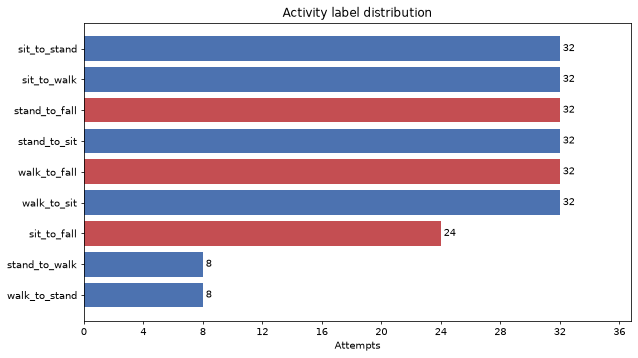

In [7]:
colors = {"Fall": "#c44e52", "Non-fall": "#4c72b0", "Unmapped": "#888888"}
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")

bars = ax.barh(
    label_distribution["activity_label"].fillna("(missing)"),
    label_distribution["attempts"],
    color=label_distribution["class"].map(colors),
)
ax.bar_label(bars, padding=3)
ax.invert_yaxis()
ax.set(title="Activity label distribution", xlabel="Attempts")
ax.margins(x=0.15)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

plt.show()


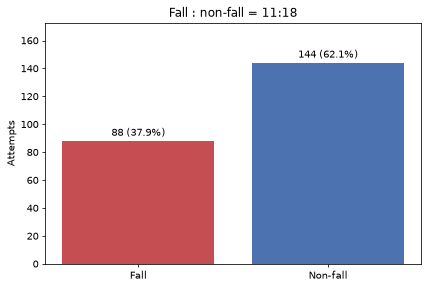

In [8]:
fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")

bars = ax.bar(
    class_distribution.index, class_distribution["attempts"],
    color=[colors[name] for name in class_distribution.index],
)
ax.bar_label(
    bars,
    labels=[
        f"{row.attempts} ({row.percent:.1f}%)"
        for row in class_distribution.itertuples()
    ],
    padding=3,
)
ax.set(title=f"Fall : non-fall = {ratio}", ylabel="Attempts")
ax.margins(y=0.2)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.show()


# CSI examples for fall and non-fall activities

In [9]:
from fall_detection.analysis.phase_signals import phase_signal_from_packets
from fall_detection.analysis.phase_motion import phase_change_matrix

SAMPLE_LABELS = {"Fall": "walk_to_fall", "Non-fall": "walk_to_sit"}
RECEIVER_IDS = sorted(packets["receiver_id"].dropna().unique())
START_DIRECTION, END_DIRECTION = "front", "front"
SUBCARRIER = 20
DISPLAY_BIN_SECONDS = 0.02
PHASE_LAG_SECONDS = 0.1
CALIBRATED_DETAIL_LIMIT = 0.25

sample_rows = {}
for category, label in SAMPLE_LABELS.items():
    candidates = selected_attempts.loc[
        selected_attempts["activity_label"].eq(label)
        & selected_attempts["start_direction"].eq(START_DIRECTION)
        & selected_attempts["end_direction"].eq(END_DIRECTION)
        & selected_attempts["quality"].ne("bad")
    ].sort_values(["trial_ordinal", "attempt"])
    if candidates.empty:
        raise ValueError(f"No eligible {label} for these directions.")
    sample_rows[category] = next(candidates.itertuples(index=False))
display(pd.DataFrame([
    {"class": category, "label": row.activity_label,
     "attempt_key": row.attempt_key, "receivers": ", ".join(RECEIVER_IDS)}
    for category, row in sample_rows.items()
]))

,class,label,attempt_key,receivers
0,Fall,walk_to_fall,trials/169_walk-to-fall__start_front__end_fron...,"rx-1, rx-2, rx-3, rx-4"
1,Non-fall,walk_to_sit,trials/017_walk-to-sit__start_front__end_front...,"rx-1, rx-2, rx-3, rx-4"


In [10]:
samples = {}
for category, row in sample_rows.items():
    for receiver_id in RECEIVER_IDS:
        recording = load_receiver(row.attempt_key, receiver_id)
        signal = phase_signal_from_packets(recording)
        if signal.skipped_layout_rows:
            raise ValueError("Unsupported CSI layouts; inspect before aligning metadata.")
        matches = np.flatnonzero(signal.subcarriers == SUBCARRIER)
        if not len(matches):
            raise ValueError(f"Subcarrier {SUBCARRIER} is missing in {receiver_id}.")
        samples[category, receiver_id] = {
            "attempt": row, "signal": signal, "label": row.activity_label,
            "category": category, "receiver_id": receiver_id, "tone": matches[0],
            "metadata": recording.loc[recording["is_sensing"]].reset_index(drop=True),
            "amplitude": np.abs(signal.complex_csi).copy(),
            "raw_phase": signal.raw_phase.copy(),
            "calibrated_phase": signal.calibrated_phase.copy(),
        }
display(pd.DataFrame([
    {"class": category, "receiver": receiver_id, "attempt": s["signal"].attempt_id,
     "packets": len(s["signal"].time_seconds),
     "clock_uncertainty_us": s["signal"].sync_uncertainty_us,
     "time_source": s["signal"].time_source.replace("(BLE)", "(wireless capture sidecar)")}
    for (category, receiver_id), s in samples.items()
]))

,class,receiver,attempt,packets,clock_uncertainty_us,time_source
0,Fall,rx-1,169/01,1337,2764.592999,transmitter enqueue mapped by USB affine fit (...
1,Fall,rx-2,169/01,1344,2764.592999,transmitter enqueue mapped by USB affine fit (...
2,Fall,rx-3,169/01,1339,2764.592999,transmitter enqueue mapped by USB affine fit (...
3,Fall,rx-4,169/01,1341,2764.592999,transmitter enqueue mapped by USB affine fit (...
4,Non-fall,rx-1,017/01,1680,3920.000000,transmitter enqueue mapped by USB affine fit (...
5,Non-fall,rx-2,017/01,1669,3920.000000,transmitter enqueue mapped by USB affine fit (...
6,Non-fall,rx-3,017/01,1665,3920.000000,transmitter enqueue mapped by USB affine fit (...
7,Non-fall,rx-4,017/01,1665,3920.000000,transmitter enqueue mapped by USB affine fit (...


In [11]:
for sample in samples.values():
    meta = sample["metadata"]
    if len(meta) != len(sample["signal"].time_seconds):
        raise ValueError("Packet metadata and decoded CSI do not align.")
    sample["driver_valid"] = meta["driver_valid"].to_numpy(dtype=bool)
    for name in ("amplitude", "raw_phase", "calibrated_phase"):
        sample[name][~sample["driver_valid"]] = np.nan
    print(f"{sample['label']}/{sample['receiver_id']}: "
          f"{(~sample['driver_valid']).sum()} driver-invalid packets")

walk_to_fall/rx-1: 0 driver-invalid packets
walk_to_fall/rx-2: 0 driver-invalid packets
walk_to_fall/rx-3: 0 driver-invalid packets
walk_to_fall/rx-4: 0 driver-invalid packets
walk_to_sit/rx-1: 1 driver-invalid packets
walk_to_sit/rx-2: 0 driver-invalid packets
walk_to_sit/rx-3: 0 driver-invalid packets
walk_to_sit/rx-4: 0 driver-invalid packets


In [12]:
for sample in samples.values():
    attempt, signal = sample["attempt"], sample["signal"]
    intervals = phases.loc[
        phases["attempt_key"].eq(attempt.attempt_key)
    ].sort_values("start_ns")
    if intervals["collection_phase"].tolist() != ["countdown", "action", "recovery"]:
        raise ValueError(f"Incomplete or duplicate cues for {attempt.attempt_key}")
    bounds = dict(zip(
        intervals["collection_phase"],
        (intervals["start_ns"].to_numpy(dtype=np.int64) - signal.started_monotonic_ns) / 1e9,
    ))
    sample["cue"] = bounds["action"]
    sample["time"] = signal.time_seconds - sample["cue"]
    sample["action_end"] = bounds["recovery"] - sample["cue"]
    sample["duration"] = (signal.ended_monotonic_ns - signal.started_monotonic_ns) / 1e9
    phase_codes = sample["metadata"]["phase"].map(
        {"preparation": 0, "action": 1, "resting": 2}
    ).fillna(-1).to_numpy(dtype=int)
    for name in ("raw_phase", "calibrated_phase"):
        sample[name + "_change"] = phase_change_matrix(
            sample[name], signal.time_seconds, PHASE_LAG_SECONDS, phase_codes=phase_codes
        )

    # Each heatmap uses the last packet in a display bin, including invalid rows.
    n_bins = int(np.ceil(sample["duration"] / DISPLAY_BIN_SECONDS))
    bin_index = np.floor(signal.time_seconds / DISPLAY_BIN_SECONDS).astype(int)
    rows = np.flatnonzero((bin_index >= 0) & (bin_index < n_bins))
    bins, reverse_index = np.unique(bin_index[rows][::-1], return_index=True)
    sample["display_bins"] = bins
    sample["display_rows"] = rows[::-1][reverse_index]
    sample["display_shape"] = (len(signal.subcarriers), n_bins)
    sample["display_extent"] = (
        -sample["cue"], n_bins * DISPLAY_BIN_SECONDS - sample["cue"],
        signal.subcarriers[0] - 0.5, signal.subcarriers[-1] + 0.5,
    )

In [13]:
def receiver_figure(ylabel: str, title: str) -> tuple:
    fig, axes = plt.subplots(
        len(RECEIVER_IDS), len(SAMPLE_LABELS), squeeze=False, sharex=True, sharey=True,
        figsize=(14, 2.3 * len(RECEIVER_IDS)), layout="constrained",
    )
    left = min(-sample["cue"] for sample in samples.values())
    right = max(sample["duration"] - sample["cue"] for sample in samples.values())
    for row, receiver_id in enumerate(RECEIVER_IDS):
        for column, category in enumerate(SAMPLE_LABELS):
            sample, ax = samples[category, receiver_id], axes[row, column]
            ax.set_xlim(left, right)
            ax.set_facecolor("#eeeeee")
            ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
            ax.axvline(sample["action_end"], color="black", linestyle=":", linewidth=0.8)
            if row == 0:
                ax.set_title(f"{category}: {sample['label']} | {sample['signal'].attempt_id}")
            if column == 0:
                ax.set_ylabel(f"{receiver_id}\n{ylabel}")
            if row == len(RECEIVER_IDS) - 1:
                ax.set_xlabel("Seconds from action cue (dashed); recovery cue (dotted)")
    fig.suptitle(title)
    return fig, axes

def sample_panels(axes: np.ndarray):
    for row, receiver_id in enumerate(RECEIVER_IDS):
        for column, category in enumerate(SAMPLE_LABELS):
            yield axes[row, column], samples[category, receiver_id]

In [14]:
def display_image(sample: dict, values: np.ndarray) -> tuple:
    """Place the last packet per time bin on the display grid without interpolation."""
    matrix = np.full(sample["display_shape"], np.nan)
    matrix[:, sample["display_bins"]] = values[sample["display_rows"]].T
    return matrix, sample["display_extent"]

In [33]:
def plot_receiver_heatmaps(
    name: str, title: str, cmap_name: str, limits: tuple | None,
    colorbar_label: str, extend: str = "neither", *,
    norm: Normalize | None = None, action_margin: float | None = None,
) -> None:
    """Plot receiver/class panels with one color scale and shared cue timing."""
    fig, axes = receiver_figure("Physical subcarrier", title)
    time_limits = axes.flat[0].get_xlim()
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad("#eeeeee")
    if norm is None:
        norm = Normalize(*limits)
    for ax, sample in sample_panels(axes):
        matrix, extent = display_image(sample, sample[name])
        if isinstance(norm, LogNorm):
            matrix = np.ma.masked_less_equal(matrix, 0)
        im = ax.imshow(
            np.ma.masked_invalid(matrix), origin="lower", aspect="auto",
            extent=extent, interpolation="nearest", cmap=cmap, norm=norm,
        )
    if action_margin is not None:
        time_limits = (
            -action_margin,
            max(sample["action_end"] for sample in samples.values()) + action_margin,
        )
    axes.flat[0].set_xlim(time_limits)
    fig.colorbar(im, ax=axes.ravel().tolist(), label=colorbar_label, extend=extend)
    plt.show()

In [16]:
def plot_receiver_trace(
    name: str, title: str, ylabel: str, limits: tuple | None = None,
) -> None:
    fig, axes = receiver_figure(ylabel, title)
    for ax, sample in sample_panels(axes):
        ax.scatter(
            sample["time"], sample[name][:, sample["tone"]], s=3, alpha=0.6,
        )
        if limits is not None:
            ax.set_ylim(*limits)
    plt.show()

## Subcarrier availability across the session

In [17]:
from fall_detection.radio.preprocessing.phase import (
    DEFAULT_PHASE_AMPLITUDE_FLOOR,
    HE20_COMPACT_SLOT_INDICES,
    HE20_SLOT_INDICES,
    HE20_VALID_SUBCARRIERS,
)

COVERAGE_BIN_SECONDS = 0.02
if not np.isfinite(COVERAGE_BIN_SECONDS) or COVERAGE_BIN_SECONDS <= 0:
    raise ValueError("Coverage bin duration must be finite and positive.")

coverage_attempts = selected_attempts.sort_values(
    ["trial_ordinal", "attempt"]
).reset_index(drop=True)
if coverage_attempts.empty:
    raise ValueError("No selected attempts to display.")
coverage_receivers = sorted({
    receiver
    for receiver_list in coverage_attempts["receiver_ids"]
    for receiver in receiver_list
})
if not coverage_receivers:
    raise ValueError("No receivers in the selected attempts.")

coverage_tones = np.arange(-122, 123)
coverage_eligible = np.isin(coverage_tones, list(HE20_VALID_SUBCARRIERS))
coverage_bin_ns = int(round(COVERAGE_BIN_SECONDS * 1e9))
if coverage_bin_ns <= 0:
    raise ValueError("Bin duration must be at least one nanosecond.")
coverage_matrix = np.full(
    (len(coverage_receivers) * len(coverage_tones), len(coverage_attempts)),
    np.nan, dtype=np.float32,
)
coverage_lookup = {}
receiver_offsets = {
    receiver: index * len(coverage_tones)
    for index, receiver in enumerate(coverage_receivers)
}
he20_layouts = {
    len(HE20_COMPACT_SLOT_INDICES): HE20_COMPACT_SLOT_INDICES,
    len(HE20_SLOT_INDICES): HE20_SLOT_INDICES,
}
for column, attempt in enumerate(coverage_attempts.itertuples(index=False)):
    if pd.isna(attempt.started_monotonic_ns) or pd.isna(attempt.ended_monotonic_ns):
        raise ValueError(f"Attempt timing is incomplete: {attempt.attempt_key}")
    start, end = int(attempt.started_monotonic_ns), int(attempt.ended_monotonic_ns)
    if end <= start:
        raise ValueError(f"Invalid attempt duration: {attempt.attempt_key}")
    n_bins = (end - start + coverage_bin_ns - 1) // coverage_bin_ns
    for receiver in attempt.receiver_ids:
        row = receiver_offsets[receiver]
        coverage_matrix[row:row + len(coverage_tones), column][coverage_eligible] = 0
        coverage_lookup[(attempt.attempt_key, receiver)] = (column, row, start, end, n_bins)

coverage_columns = [
    "attempt_key", "receiver_id", "capture_time_ns", "driver_valid",
    "len", "sig_mode", "bandwidth", "stbc", "first_word", "csi_i", "csi_q",
]
coverage_ordinals = coverage_attempts["trial_ordinal"].drop_duplicates().tolist()
for batch_start in range(0, len(coverage_ordinals), 20):
    batch = coverage_ordinals[batch_start:batch_start + 20]
    recorded = session.read_packets(
        filters=[
            ("trial_ordinal", "in", batch),
            ("status", "==", "accepted"),
            ("inclusion", "!=", "exclude"),
            ("is_sensing", "==", True),
        ],
        columns=coverage_columns, arrow_backed=True,
    )
    for (attempt_key, receiver), group in recorded.groupby(
        ["attempt_key", "receiver_id"], observed=True, sort=False
    ):
        info = coverage_lookup.get((attempt_key, receiver))
        if info is None:
            continue
        column, row, start, end, n_bins = info
        group = group.loc[
            group["driver_valid"]
            & group["capture_time_ns"].ge(start)
            & group["capture_time_ns"].lt(end)
        ]
        filled = np.zeros((n_bins, len(coverage_tones)), dtype=bool)
        for layout, subset in group.groupby(
            ["len", "sig_mode", "bandwidth", "stbc", "first_word"],
            observed=True, dropna=False, sort=False,
        ):
            declared, sig_mode, bandwidth, stbc, first_word = map(int, layout)
            if sig_mode != 4 or bandwidth != 0 or stbc != 0:
                raise ValueError(f"Unsupported HE20 layout: {layout}")
            indices = he20_layouts.get(declared // 2)
            if declared % 2 or indices is None:
                raise ValueError(f"Unsupported CSI length: {declared}")
            real = np.stack(subset["csi_i"].to_numpy())
            imag = np.stack(subset["csi_q"].to_numpy())
            if real.shape != imag.shape or real.shape[1] != len(indices):
                raise ValueError("I/Q array length does not match CSI metadata.")
            physical = np.asarray(indices)
            keep = (physical >= coverage_tones[0]) & (physical <= coverage_tones[-1])
            usable = np.isfinite(real) & np.isfinite(imag)
            usable &= np.hypot(real, imag) >= DEFAULT_PHASE_AMPLITUDE_FLOOR
            if first_word:
                usable[:, :2] = False
            bin_index = (
                subset["capture_time_ns"].to_numpy(dtype=np.int64) - start
            ) // coverage_bin_ns
            mapped = np.zeros((len(subset), len(coverage_tones)), dtype=bool)
            mapped[:, physical[keep] - coverage_tones[0]] = usable[:, keep]
            np.logical_or.at(filled, bin_index, mapped)
        result = 100 * filled.sum(axis=0) / n_bins
        result[~coverage_eligible] = np.nan
        coverage_matrix[row:row + len(coverage_tones), column] = result

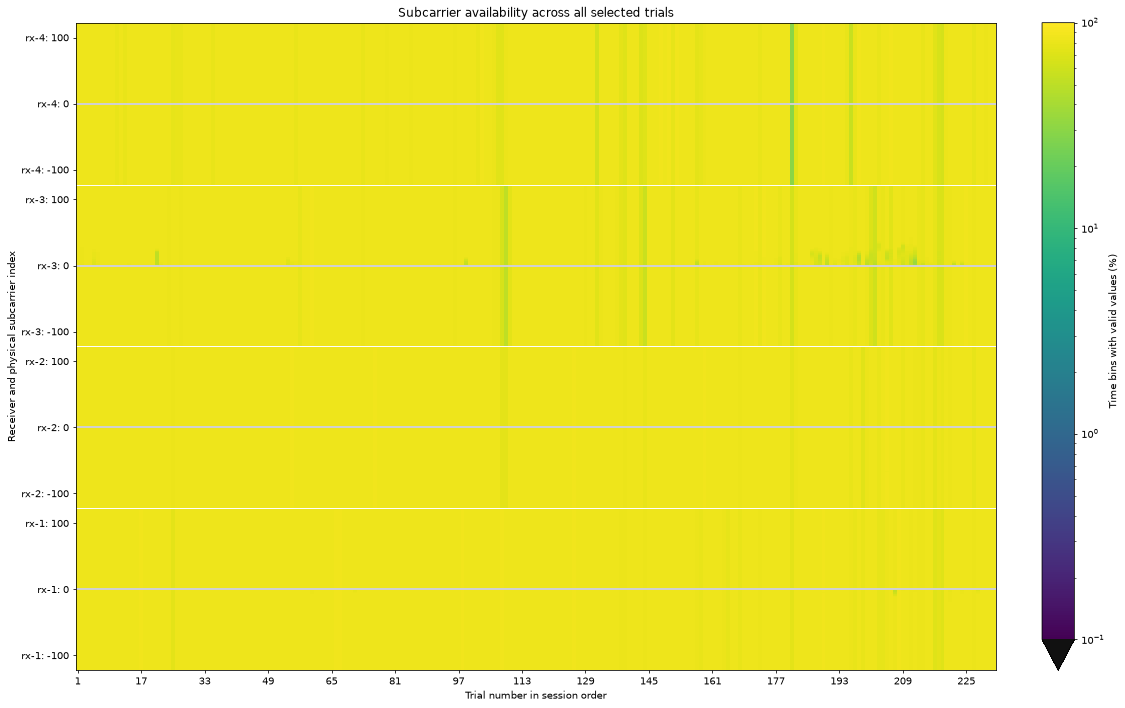

,receiver,mean_availability_percent
0,rx-1,83.49
1,rx-2,83.54
2,rx-3,82.31
3,rx-4,82.40


In [34]:
fig, ax = plt.subplots(figsize=(16, 10), layout="constrained")
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("#d0d0d0")
cmap.set_under("#111111")
im = ax.imshow(
    np.ma.masked_invalid(coverage_matrix), aspect="auto", origin="lower",
    interpolation="nearest", cmap=cmap, norm=LogNorm(vmin=0.1, vmax=100),
)
tone_ticks = [-100, 0, 100]
ticks = [
    index * len(coverage_tones) + tone - coverage_tones[0]
    for index in range(len(coverage_receivers))
    for tone in tone_ticks
]
labels = [
    f"{receiver}: {tone}"
    for receiver in coverage_receivers
    for tone in tone_ticks
]
ax.set_yticks(ticks, labels)
for boundary in range(1, len(coverage_receivers)):
    ax.axhline(boundary * len(coverage_tones) - 0.5, color="white", linewidth=1)
step = max(1, int(np.ceil(len(coverage_attempts) / 15)))
tick_columns = np.arange(0, len(coverage_attempts), step)
ax.set_xticks(tick_columns, coverage_attempts.iloc[tick_columns]["trial_ordinal"].astype(str))
ax.set(
    title="Subcarrier availability across all selected trials",
    xlabel="Trial number in session order",
    ylabel="Receiver and physical subcarrier index",
)
fig.colorbar(im, ax=ax, label="Time bins with valid values (%)", extend="min")
plt.show()

coverage_per_receiver = pd.DataFrame([
    {
        "receiver": receiver,
        "mean_availability_percent": float(np.nanmean(
            coverage_matrix[index * len(coverage_tones):(index + 1) * len(coverage_tones)]
        )),
    }
    for index, receiver in enumerate(coverage_receivers)
])
display(coverage_per_receiver.round(2))

## Amplitude

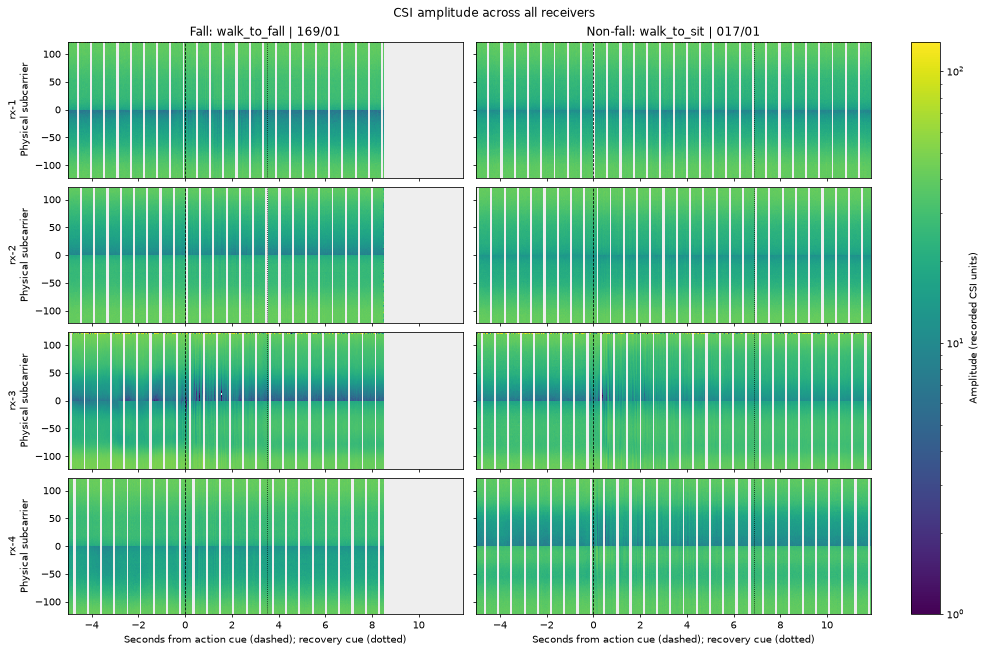

In [35]:
positive_amplitudes = [
    s["amplitude"][np.isfinite(s["amplitude"]) & (s["amplitude"] > 0)]
    for s in samples.values()
]
amplitude_min = min(values.min() for values in positive_amplitudes if len(values))
amplitude_max = max(np.nanmax(s["amplitude"]) for s in samples.values())
amplitude_max = max(amplitude_max, amplitude_min * (1 + 1e-6))
plot_receiver_heatmaps(
    "amplitude", "CSI amplitude across all receivers", "viridis",
    None, "Amplitude (recorded CSI units)",
    norm=LogNorm(vmin=amplitude_min, vmax=amplitude_max),
)

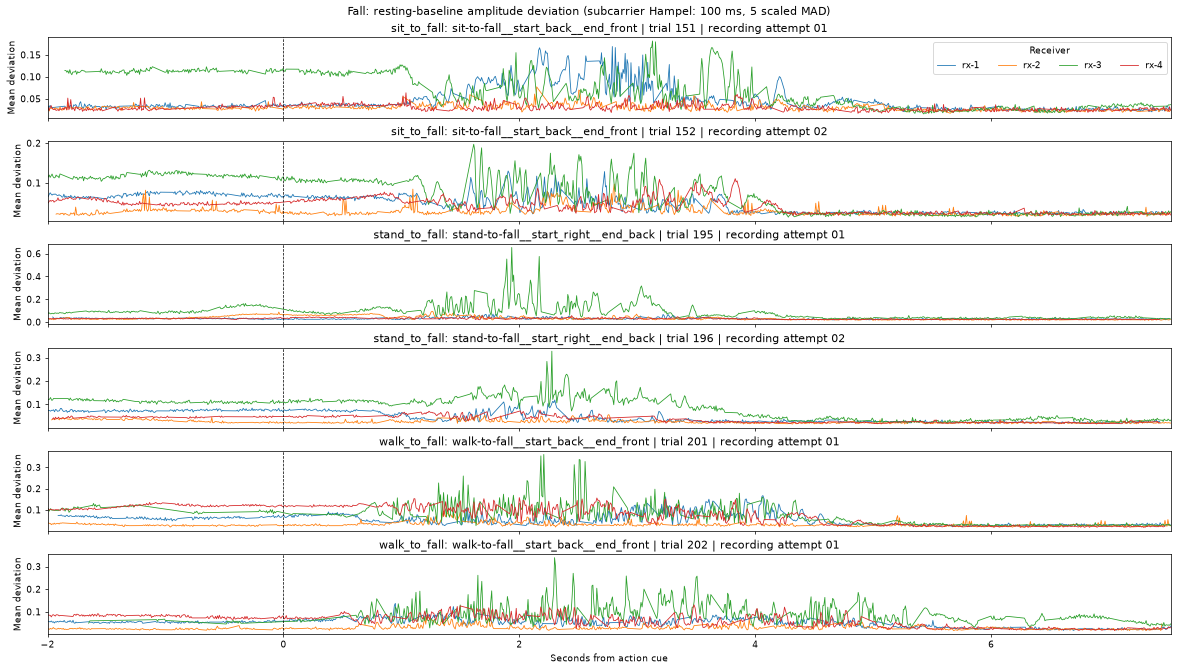

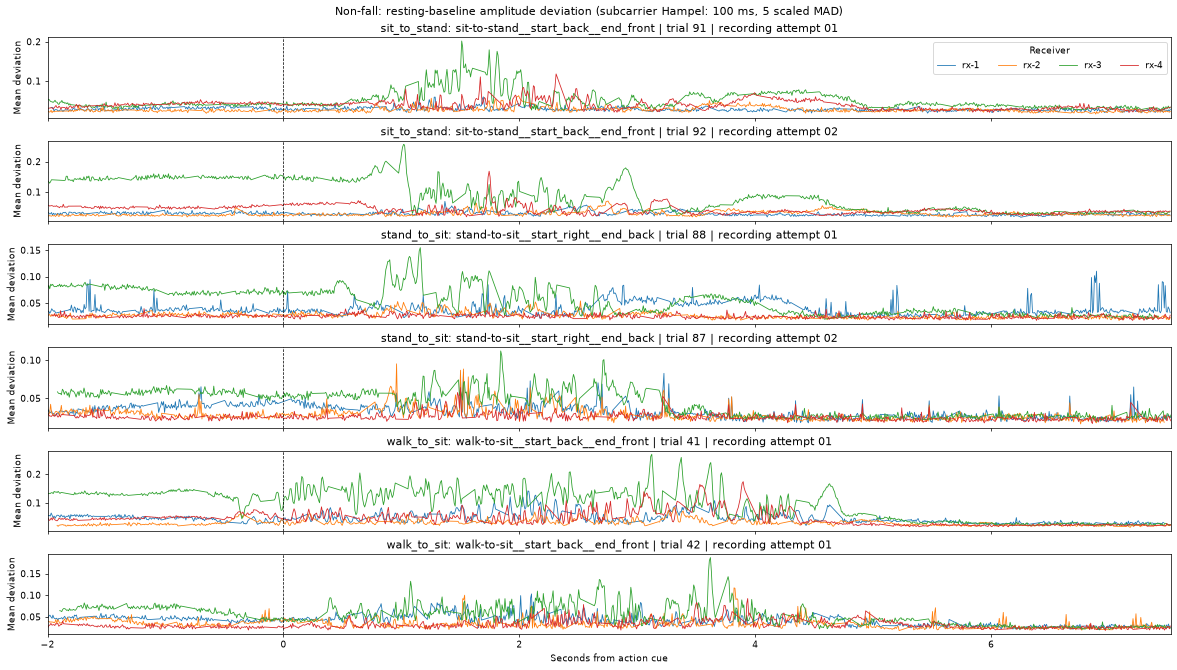

Subcarrier Hampel replaced 138,953 of 16,240,632 evaluated values for plotting.


In [75]:
import warnings

HAMPEL_WINDOW_SECONDS = 0.1
HAMPEL_MIN_PERIODS = 5
HAMPEL_THRESHOLD = 5.0
MOTION_GROUPS = (
    ("sit_to_fall", "sit-to-fall__start_back__end_front"),
    ("sit_to_stand", "sit-to-stand__start_back__end_front"),
    ("stand_to_fall", "stand-to-fall__start_right__end_back"),
    ("stand_to_sit", "stand-to-sit__start_right__end_back"),
    ("walk_to_fall", "walk-to-fall__start_back__end_front"),
    ("walk_to_sit", "walk-to-sit__start_back__end_front"),
)
MOTION_CACHE_KEY = (
    "per-subcarrier-hampel-distinct-trials-v3",
    HAMPEL_WINDOW_SECONDS,
    HAMPEL_MIN_PERIODS,
    HAMPEL_THRESHOLD,
    MOTION_GROUPS,
)

if globals().get("_motion_cache_key") != MOTION_CACHE_KEY:
    motion_candidates = selected_attempts.loc[
        selected_attempts["quality"].ne("bad")
        & selected_attempts["receiver_ids"].map(
            lambda ids: set(RECEIVER_IDS).issubset(ids)
        )
    ].copy()

    motion_attempts = []
    for label, scenario_id in MOTION_GROUPS:
        options = motion_candidates.loc[
            motion_candidates["activity_label"].eq(label)
            & motion_candidates["scenario_id"].eq(scenario_id)
        ].sort_values(["trial_ordinal", "attempt"])
        options = options.drop_duplicates("trial_ordinal", keep="first").head(2)
        options = options.sort_values(["attempt", "trial_ordinal"])
        if len(options) != 2 or options["trial_ordinal"].nunique() != 2:
            raise ValueError(
                f"Expected two distinct trials for {label}/{scenario_id}."
            )
        for _, attempt in options.iterrows():
            motion_attempts.append((label, scenario_id, attempt))
    
    motion_signals = {}
    hampel_replaced = 0
    hampel_tested = 0
    for label, scenario_id, attempt in motion_attempts:
        action_cue = phases.loc[
            phases["attempt_key"].eq(attempt["attempt_key"])
            & phases["collection_phase"].eq("action"),
            "start_ns",
        ]
        if len(action_cue) != 1:
            raise ValueError(f"Expected one action cue for {attempt['attempt_key']}.")
    
        for receiver_id in RECEIVER_IDS:
            recording = load_receiver(attempt["attempt_key"], receiver_id)
            signal = phase_signal_from_packets(recording)
            if signal.skipped_layout_rows:
                raise ValueError("Unsupported CSI layout in selected scenario.")
            metadata = recording.loc[recording["is_sensing"]].reset_index(drop=True)
            if len(metadata) != len(signal.time_seconds):
                raise ValueError("Packet metadata and decoded CSI do not align.")
    
            amplitude = np.abs(signal.complex_csi)
            valid_slots = (
                np.isfinite(signal.raw_phase)
                & metadata["driver_valid"].to_numpy(dtype=bool)[:, None]
            )
            amplitude[~valid_slots] = np.nan
            resting = metadata["phase"].eq("resting").to_numpy()
            if not resting.any():
                raise ValueError(f"No resting packets for {label}/{receiver_id}.")
    
            baseline_tones = np.isfinite(amplitude[resting]).any(axis=0)
            baseline = np.full(amplitude.shape[1], np.nan)
            baseline[baseline_tones] = np.nanmean(
                amplitude[resting][:, baseline_tones], axis=0,
            )
            baseline_tones &= np.isfinite(baseline) & (baseline > 0)
            if not baseline_tones.any():
                raise ValueError(f"No valid resting amplitudes for {label}/{receiver_id}.")
    
            # Filter each valid subcarrier in a centered 100 ms time window.
            filtered_amplitude = amplitude.copy()
            tone_positions = np.flatnonzero(baseline_tones)
            packet_times = signal.time_seconds
            half_window = HAMPEL_WINDOW_SECONDS / 2
            starts = np.searchsorted(
                packet_times, packet_times - half_window, side="left",
            )
            stops = np.searchsorted(
                packet_times, packet_times + half_window, side="right",
            )
            window_sizes = stops - starts

            for window_size in np.unique(window_sizes):
                if window_size < HAMPEL_MIN_PERIODS:
                    continue
                rows = np.flatnonzero(window_sizes == window_size)
                indices = starts[rows, None] + np.arange(window_size)
                windows = amplitude[indices][:, :, baseline_tones]
                valid_tones = (
                    np.isfinite(windows).sum(axis=1) >= HAMPEL_MIN_PERIODS
                )
                with warnings.catch_warnings():
                    warnings.filterwarnings(
                        "ignore", message="All-NaN slice encountered",
                        category=RuntimeWarning,
                    )
                    local_median = np.nanmedian(windows, axis=1)
                    local_mad = np.nanmedian(
                        np.abs(windows - local_median[:, None, :]), axis=1,
                    )
                center = amplitude[rows][:, baseline_tones]
                outliers = (
                    valid_tones
                    & (local_mad > 0)
                    & np.isfinite(local_median)
                    & (np.abs(center - local_median)
                       > HAMPEL_THRESHOLD * 1.4826 * local_mad)
                )
                for row_index, row in enumerate(rows):
                    selected = outliers[row_index]
                    filtered_amplitude[
                        row, tone_positions[selected]
                    ] = local_median[row_index, selected]
                hampel_replaced += int(outliers.sum())
                hampel_tested += int(valid_tones.sum())

            deviation = np.abs(
                (filtered_amplitude[:, baseline_tones] - baseline[baseline_tones])
                / (baseline[baseline_tones] + 1e-8)
            )
            counts = np.isfinite(deviation).sum(axis=1)
            motion = np.full(len(signal.time_seconds), np.nan)
            valid_rows = counts > 0
            motion[valid_rows] = np.nansum(
                deviation[valid_rows], axis=1,
            ) / counts[valid_rows]
            cue_seconds = (
                int(action_cue.iloc[0]) - signal.started_monotonic_ns
            ) / 1e9
            motion_signals[label, scenario_id, attempt["attempt_key"], receiver_id] = (
                signal.time_seconds - cue_seconds,
                motion,
            )
    _motion_cache_key = MOTION_CACHE_KEY

action_durations = []
for _, _, attempt in motion_attempts:
    action_phase = phases.loc[
        phases["attempt_key"].eq(attempt["attempt_key"])
        & phases["collection_phase"].eq("action")
    ]
    if len(action_phase) != 1:
        raise ValueError(f"Expected one action interval for {attempt['attempt_key']}.")
    action_durations.append(
        (int(action_phase["end_ns"].iloc[0]) - int(action_phase["start_ns"].iloc[0]))
        / 1e9
    )
x_limits = (-2.0, max(action_durations) + 1.5)

for activity_class in ("Fall", "Non-fall"):
    group = [item for item in motion_attempts if label_to_class[item[0]].lower() == activity_class.lower()]
    fig, axes = plt.subplots(
        len(group), 1, figsize=(18, 1.7 * len(group)),
        sharex=True, layout="constrained", squeeze=False,
    )
    axes = axes[:, 0]
    axes[0].set_xlim(*x_limits)
    for ax, (label, scenario_id, attempt) in zip(axes, group):
        for receiver_id in RECEIVER_IDS:
            time, motion = motion_signals[label, scenario_id, attempt["attempt_key"], receiver_id]
            visible = (time >= x_limits[0]) & (time <= x_limits[1])
            ax.plot(time[visible], motion[visible], linewidth=0.9, label=receiver_id)
        ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
        ax.set(
            title=(f"{label}: {scenario_id} | trial {attempt['trial_ordinal']} | "
                   f"recording attempt {int(attempt['attempt']):02d}"),
            ylabel="Mean deviation",
        )
    axes[-1].set_xlabel("Seconds from action cue")
    axes[0].legend(title="Receiver", ncol=len(RECEIVER_IDS))
    fig.set_dpi(65)
    fig.suptitle(
        f"{activity_class}: resting-baseline amplitude deviation "
        f"(subcarrier Hampel: {HAMPEL_WINDOW_SECONDS * 1000:.0f} ms, 5 scaled MAD)"
    )
    plt.show()
print(
    f"Subcarrier Hampel replaced {hampel_replaced:,} of "
    f"{hampel_tested:,} evaluated values for plotting."
)

In [77]:
# Compare the two displayed trials of each scenario, aligned to the action cue.
CORRELATION_STEP = 0.02  # seconds
MAX_INTERPOLATION_GAP = 0.1  # seconds
MAX_LAG = 2.0  # seconds
MIN_OVERLAP = 50  # grid points

def correlation_grid(time, values, grid):
    """Interpolate within short gaps between valid plotted samples."""
    valid = np.isfinite(time) & np.isfinite(values)
    time, values = time[valid], values[valid]
    if len(time) < 2:
        return np.full(grid.shape, np.nan)
    right = np.searchsorted(time, grid, side="left")
    result = np.full(grid.shape, np.nan)
    inside = (right > 0) & (right < len(time))
    idx = np.flatnonzero(inside)
    left, right_idx = right[idx] - 1, right[idx]
    short = (time[right_idx] - time[left]) <= MAX_INTERPOLATION_GAP
    idx = idx[short]
    result[idx] = np.interp(grid[idx], time, values)
    return result

def overlap_pearson(a, b):
    valid = np.isfinite(a) & np.isfinite(b)
    if valid.sum() < MIN_OVERLAP:
        return np.nan, int(valid.sum())
    a, b = a[valid], b[valid]
    if np.std(a) == 0 or np.std(b) == 0:
        return np.nan, len(a)
    return float(np.corrcoef(a, b)[0, 1]), len(a)

correlation_rows = []
grid = np.arange(x_limits[0], x_limits[1] + CORRELATION_STEP / 2, CORRELATION_STEP)
for label, scenario_id in MOTION_GROUPS:
    trials = [
        item for item in motion_attempts
        if item[0] == label and item[1] == scenario_id
    ]
    if len(trials) != 2:
        raise ValueError(f"Expected two displayed trials for {scenario_id}.")
    first, second = trials
    for receiver in RECEIVER_IDS:
        first_time, first_values = motion_signals[
            label, scenario_id, first[2]["attempt_key"], receiver
        ]
        second_time, second_values = motion_signals[
            label, scenario_id, second[2]["attempt_key"], receiver
        ]
        a = correlation_grid(first_time, first_values, grid)
        b = correlation_grid(second_time, second_values, grid)
        pearson, overlap = overlap_pearson(a, b)
        lag_results = []
        for lag in range(-round(MAX_LAG / CORRELATION_STEP), round(MAX_LAG / CORRELATION_STEP) + 1):
            # Positive lag compares trial 1 at t with trial 2 at t + lag.
            if lag > 0:
                x, y = a[:-lag], b[lag:]
            elif lag < 0:
                x, y = a[-lag:], b[:lag]
            else:
                x, y = a, b
            value, count = overlap_pearson(x, y)
            if np.isfinite(value):
                lag_results.append((value, lag * CORRELATION_STEP, count))
        peak, peak_lag, peak_overlap = (
            max(lag_results, key=lambda row: abs(row[0]))
            if lag_results else (np.nan, np.nan, 0)
        )
        correlation_rows.append({
            "activity": label, "scenario": scenario_id,
            "trial_1": first[2]["attempt_id"], "trial_2": second[2]["attempt_id"],
            "receiver": receiver, "pearson_r": pearson, "overlap_points": overlap,
            "peak_cross_correlation": peak, "peak_lag_seconds": peak_lag,
            "peak_overlap_points": peak_overlap,
        })

correlations = pd.DataFrame(correlation_rows)
display(correlations.round(3))


,activity,scenario,trial_1,trial_2,receiver,pearson_r,overlap_points,peak_cross_correlation,peak_lag_seconds,peak_overlap_points
0,sit_to_fall,sit-to-fall__start_back__end_front,151/01,152/02,rx-1,0.245,296,0.421,-2.00,252
1,sit_to_fall,sit-to-fall__start_back__end_front,151/01,152/02,rx-2,0.490,290,0.546,0.04,292
2,sit_to_fall,sit-to-fall__start_back__end_front,151/01,152/02,rx-3,0.765,284,0.824,-0.12,287
3,sit_to_fall,sit-to-fall__start_back__end_front,151/01,152/02,rx-4,0.481,294,0.538,0.10,292
4,sit_to_stand,sit-to-stand__start_back__end_front,091/01,092/02,rx-1,0.108,295,0.454,0.48,299
5,sit_to_stand,sit-to-stand__start_back__end_front,091/01,092/02,rx-2,0.219,297,0.612,0.76,270
6,sit_to_stand,sit-to-stand__start_back__end_front,091/01,092/02,rx-3,0.058,293,0.460,-1.78,251
7,sit_to_stand,sit-to-stand__start_back__end_front,091/01,092/02,rx-4,0.175,296,0.399,1.12,261
8,stand_to_fall,stand-to-fall__start_right__end_back,195/01,196/02,rx-1,0.227,309,0.451,-1.34,292
9,stand_to_fall,stand-to-fall__start_right__end_back,195/01,196/02,rx-2,0.071,303,0.654,1.50,285


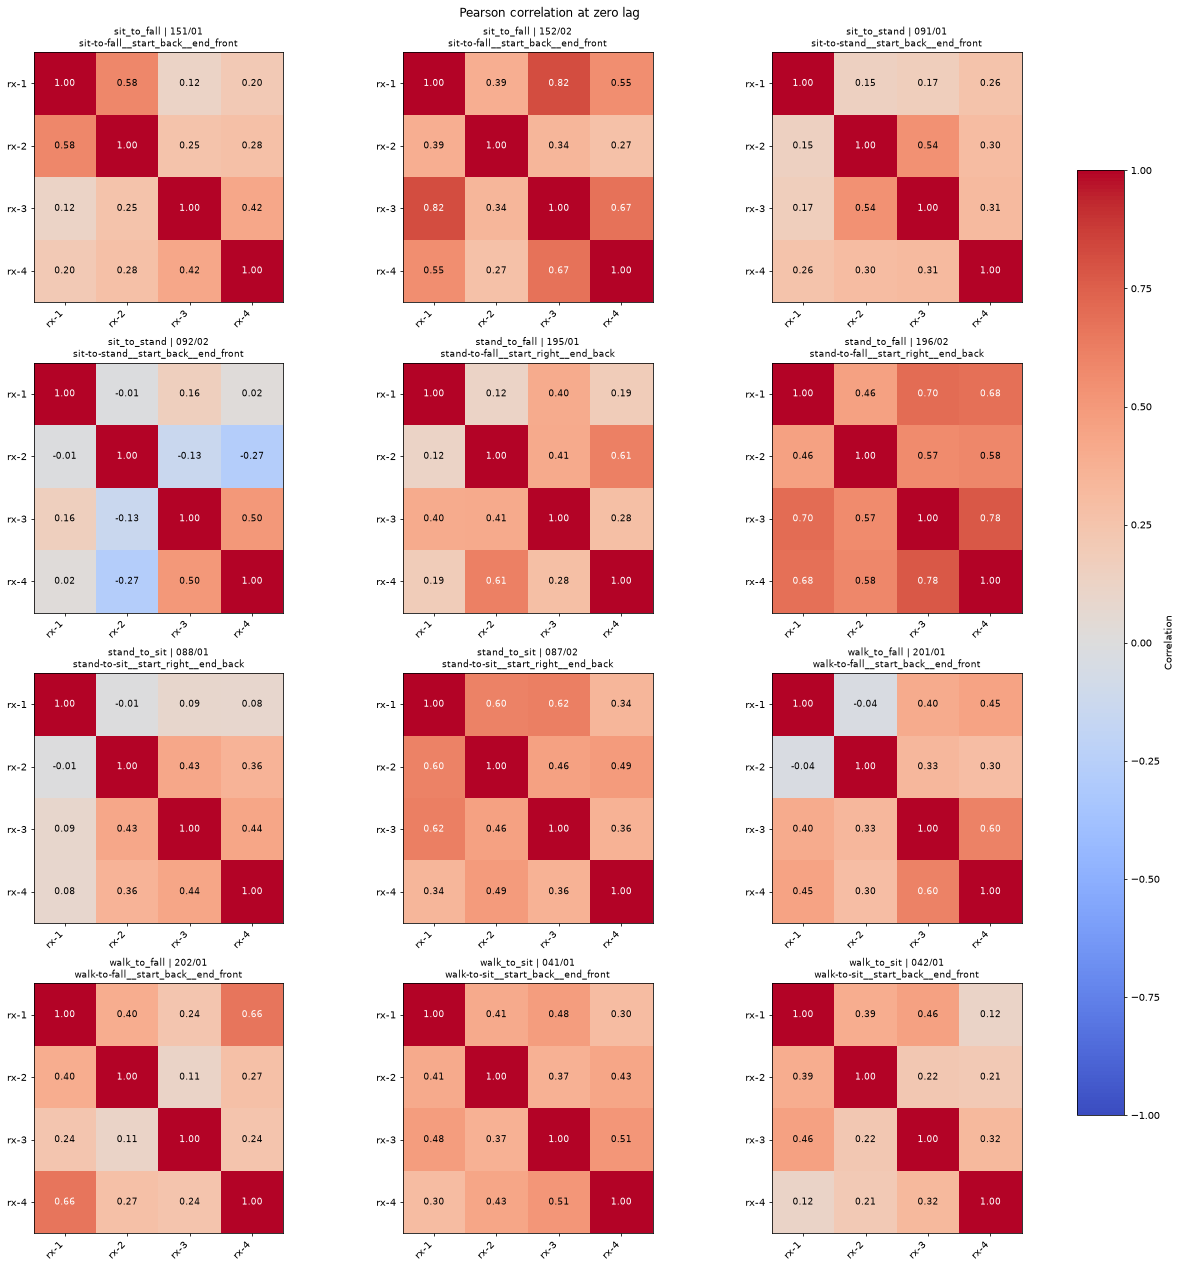

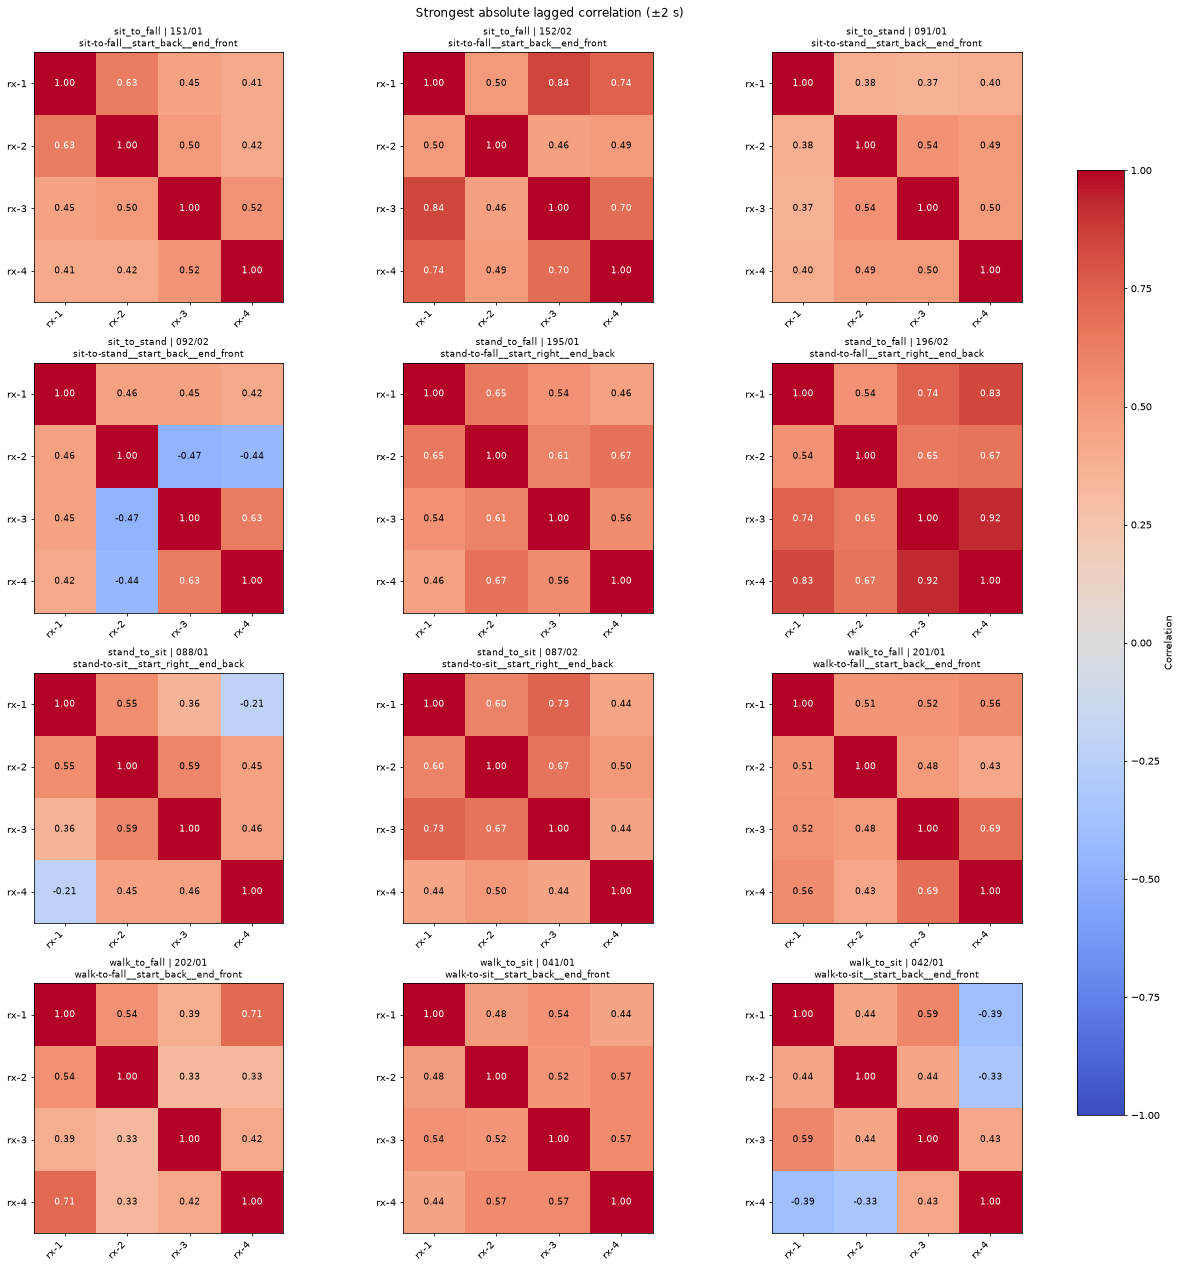

In [78]:
# Receiver correlations for each displayed recording, using the same
# filtered amplitude-deviation signals and interpolation as above.
receiver_correlation_matrices = {}
receiver_cross_correlation_matrices = {}
grid = np.arange(x_limits[0], x_limits[1] + CORRELATION_STEP / 2, CORRELATION_STEP)
lag_limit = round(MAX_LAG / CORRELATION_STEP)

for label, scenario_id, attempt in motion_attempts:
    key = (label, scenario_id, attempt["attempt_key"])
    aligned = []
    for receiver in RECEIVER_IDS:
        time, values = motion_signals[label, scenario_id, attempt["attempt_key"], receiver]
        aligned.append(correlation_grid(time, values, grid))

    n = len(RECEIVER_IDS)
    pearson_matrix = np.full((n, n), np.nan)
    cross_matrix = np.full((n, n), np.nan)
    for i in range(n):
        for j in range(i, n):
            pearson_matrix[i, j], _ = overlap_pearson(aligned[i], aligned[j])
            pearson_matrix[j, i] = pearson_matrix[i, j]
            lagged = []
            for lag in range(-lag_limit, lag_limit + 1):
                if lag > 0:
                    a, b = aligned[i][:-lag], aligned[j][lag:]
                elif lag < 0:
                    a, b = aligned[i][-lag:], aligned[j][:lag]
                else:
                    a, b = aligned[i], aligned[j]
                value, _ = overlap_pearson(a, b)
                if np.isfinite(value):
                    lagged.append(value)
            if lagged:
                cross_matrix[i, j] = max(lagged, key=abs)
                cross_matrix[j, i] = cross_matrix[i, j]
    receiver_correlation_matrices[key] = pearson_matrix
    receiver_cross_correlation_matrices[key] = cross_matrix

for title, matrices in (
    ("Pearson correlation at zero lag", receiver_correlation_matrices),
    ("Strongest absolute lagged correlation (±2 s)", receiver_cross_correlation_matrices),
):
    columns = 3
    rows = (len(motion_attempts) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(18, 4.5 * rows), squeeze=False, layout="constrained")
    for ax, (label, scenario_id, attempt) in zip(axes.flat, motion_attempts):
        key = (label, scenario_id, attempt["attempt_key"])
        matrix = matrices[key]
        image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
        ax.set_xticks(range(len(RECEIVER_IDS)), RECEIVER_IDS, rotation=45, ha="right")
        ax.set_yticks(range(len(RECEIVER_IDS)), RECEIVER_IDS)
        ax.set_title(f"{label} | {attempt['attempt_id']}\n{scenario_id}", fontsize=9)
        for i in range(len(RECEIVER_IDS)):
            for j in range(len(RECEIVER_IDS)):
                value = matrix[i, j]
                ax.text(j, i, f"{value:.2f}" if np.isfinite(value) else "—",
                        ha="center", va="center", fontsize=9,
                        color="white" if np.isfinite(value) and abs(value) > 0.6 else "black")
    for ax in list(axes.flat)[len(motion_attempts):]:
        ax.set_visible(False)
    fig.colorbar(image, ax=axes.ravel().tolist(), label="Correlation", shrink=0.8)
    fig.suptitle(title)
    plt.show()


### Amplitude around the action

Change color scale: ±4.25 CSI units (pooled p99 of absolute changes)


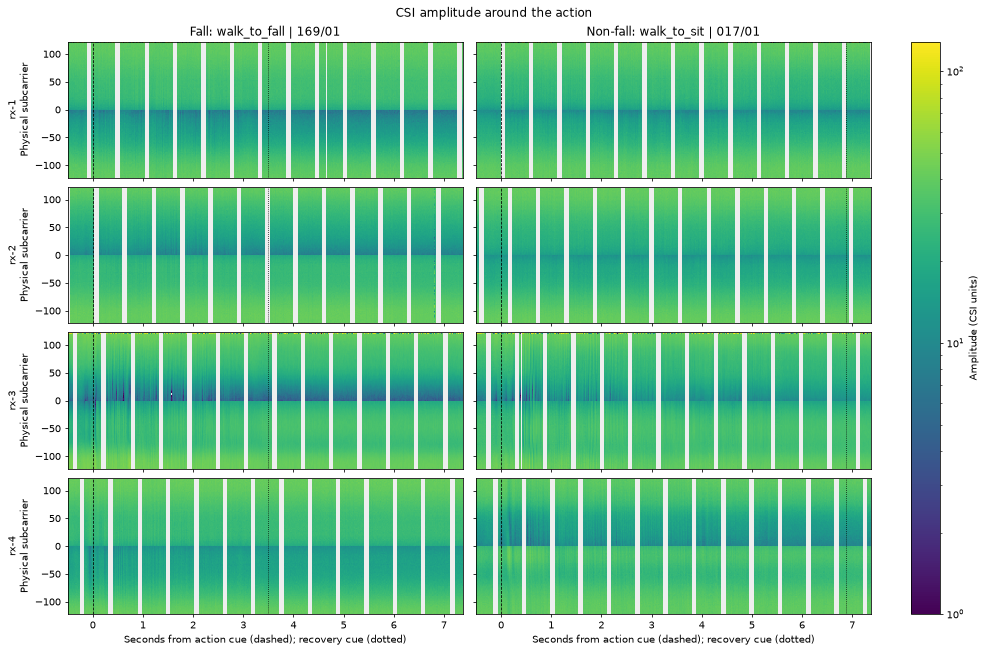

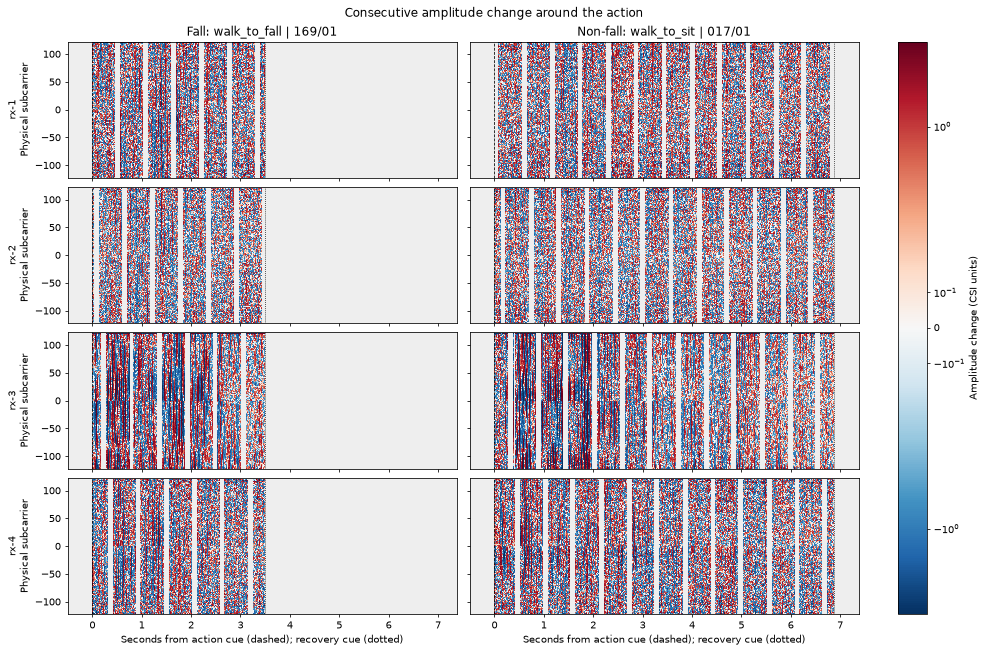

In [36]:
ACTION_MARGIN_SECONDS = 0.5
MAX_CHANGE_GAP_SECONDS = 0.1

for sample in samples.values():
    amplitude = sample["amplitude"]
    time = sample["time"]
    change = np.full_like(amplitude, np.nan)
    if len(time) > 1:
        gap = np.diff(time)
        action = (time >= 0) & (time < sample["action_end"])
        valid_pair = (
            action[1:] & action[:-1]
            & (gap > 0) & (gap <= MAX_CHANGE_GAP_SECONDS)
        )
        valid = (
            valid_pair[:, None]
            & np.isfinite(amplitude[1:])
            & np.isfinite(amplitude[:-1])
        )
        np.subtract(amplitude[1:], amplitude[:-1], out=change[1:], where=valid)
    sample["amplitude_change"] = change

finite_changes = [
    sample["amplitude_change"][np.isfinite(sample["amplitude_change"])]
    for sample in samples.values()
]
pooled_changes = np.concatenate(finite_changes)
change_max = max(
    np.quantile(np.abs(pooled_changes), 0.99) if len(pooled_changes) else 1,
    np.finfo(float).eps,
)
print(f"Change color scale: ±{change_max:.2f} CSI units (pooled p99 of absolute changes)")

change_linthresh = min(1.0, change_max / 10)

for field, title, cmap_name, norm, colorbar_label in (
    ("amplitude", "CSI amplitude around the action", "viridis",
     LogNorm(vmin=amplitude_min, vmax=amplitude_max), "Amplitude (CSI units)"),
    ("amplitude_change", "Consecutive amplitude change around the action", "RdBu_r",
     SymLogNorm(linthresh=change_linthresh, vmin=-change_max, vmax=change_max),
     "Amplitude change (CSI units)"),
):
    plot_receiver_heatmaps(
        field, title, cmap_name, None, colorbar_label,
        norm=norm, action_margin=ACTION_MARGIN_SECONDS,
    )

## Phase

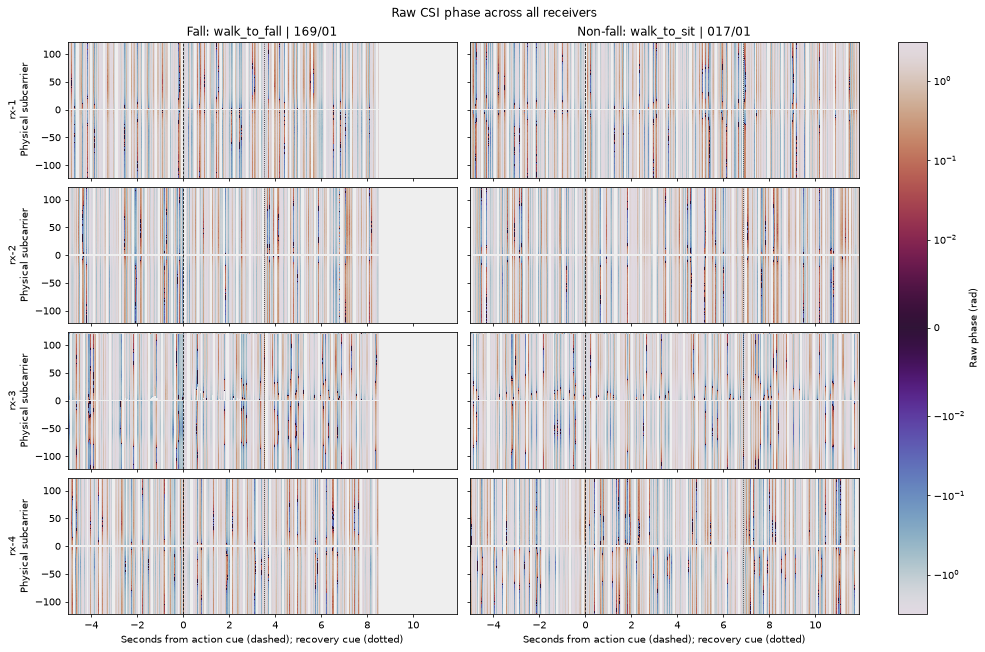

In [37]:
plot_receiver_heatmaps(
    "raw_phase", "Raw CSI phase across all receivers", "twilight",
    None, "Raw phase (rad)",
    norm=SymLogNorm(linthresh=0.01, vmin=-np.pi, vmax=np.pi),
)

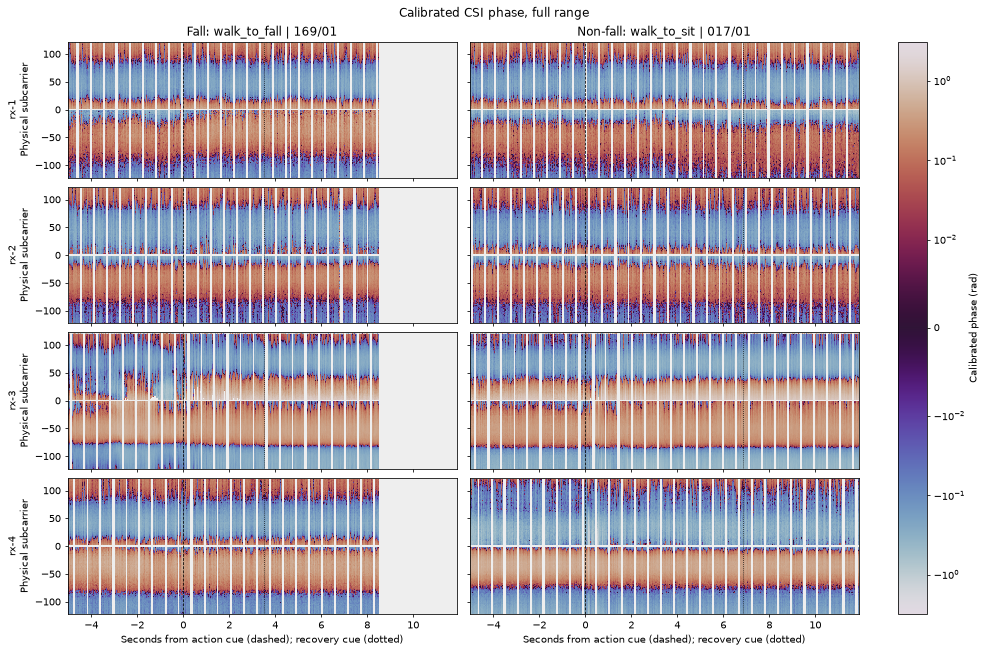

In [38]:
plot_receiver_heatmaps(
    "calibrated_phase", "Calibrated CSI phase, full range", "twilight",
    None, "Calibrated phase (rad)",
    norm=SymLogNorm(linthresh=0.01, vmin=-np.pi, vmax=np.pi),
)

Fall/rx-1: 10.43% outside ±0.25 rad
Fall/rx-2: 7.08% outside ±0.25 rad
Fall/rx-3: 35.62% outside ±0.25 rad
Fall/rx-4: 21.71% outside ±0.25 rad
Non-fall/rx-1: 9.31% outside ±0.25 rad
Non-fall/rx-2: 3.61% outside ±0.25 rad
Non-fall/rx-3: 43.59% outside ±0.25 rad
Non-fall/rx-4: 33.69% outside ±0.25 rad


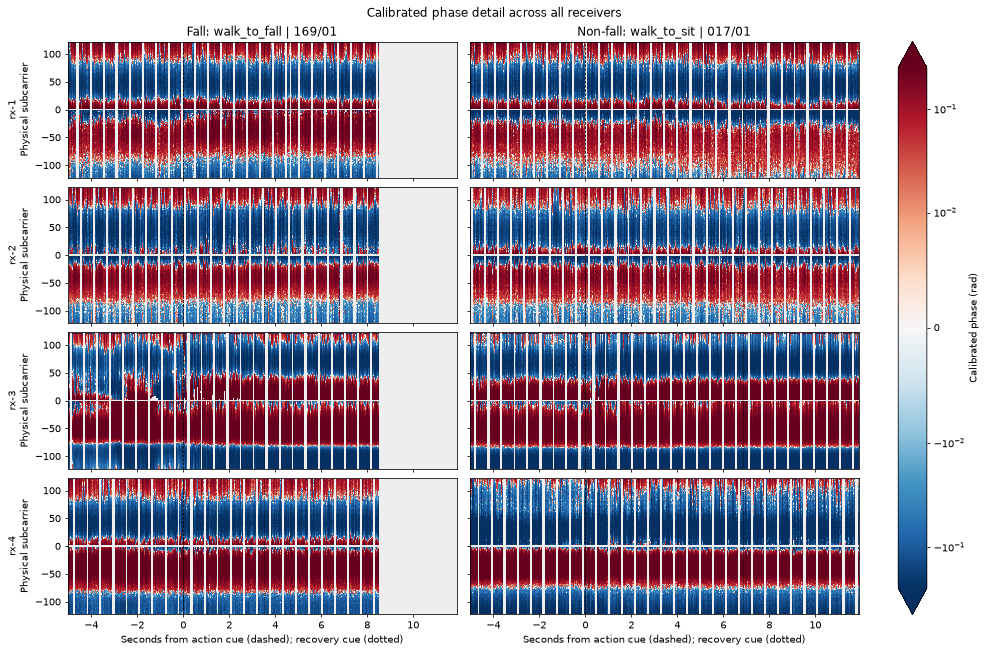

In [39]:
if not np.isfinite(CALIBRATED_DETAIL_LIMIT) or CALIBRATED_DETAIL_LIMIT <= 0:
    raise ValueError("CALIBRATED_DETAIL_LIMIT must be finite and positive.")
for (category, receiver_id), sample in samples.items():
    values = sample["calibrated_phase"]
    finite = values[np.isfinite(values)]
    fraction = (np.abs(finite) > CALIBRATED_DETAIL_LIMIT).mean() if len(finite) else np.nan
    print(f"{category}/{receiver_id}: {fraction:.2%} outside "
          f"±{CALIBRATED_DETAIL_LIMIT:g} rad")
plot_receiver_heatmaps(
    "calibrated_phase", "Calibrated phase detail across all receivers", "RdBu_r",
    None, "Calibrated phase (rad)", extend="both",
    norm=SymLogNorm(
        linthresh=0.01, vmin=-CALIBRATED_DETAIL_LIMIT,
        vmax=CALIBRATED_DETAIL_LIMIT,
    ),
)

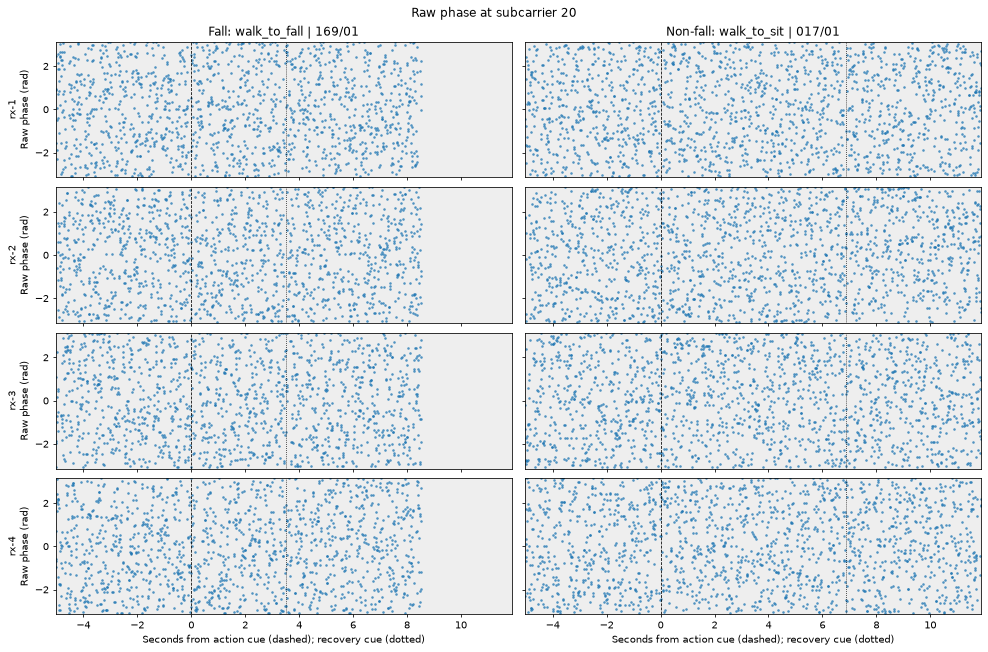

In [25]:
plot_receiver_trace(
    "raw_phase", f"Raw phase at subcarrier {SUBCARRIER}",
    "Raw phase (rad)", (-np.pi, np.pi),
)

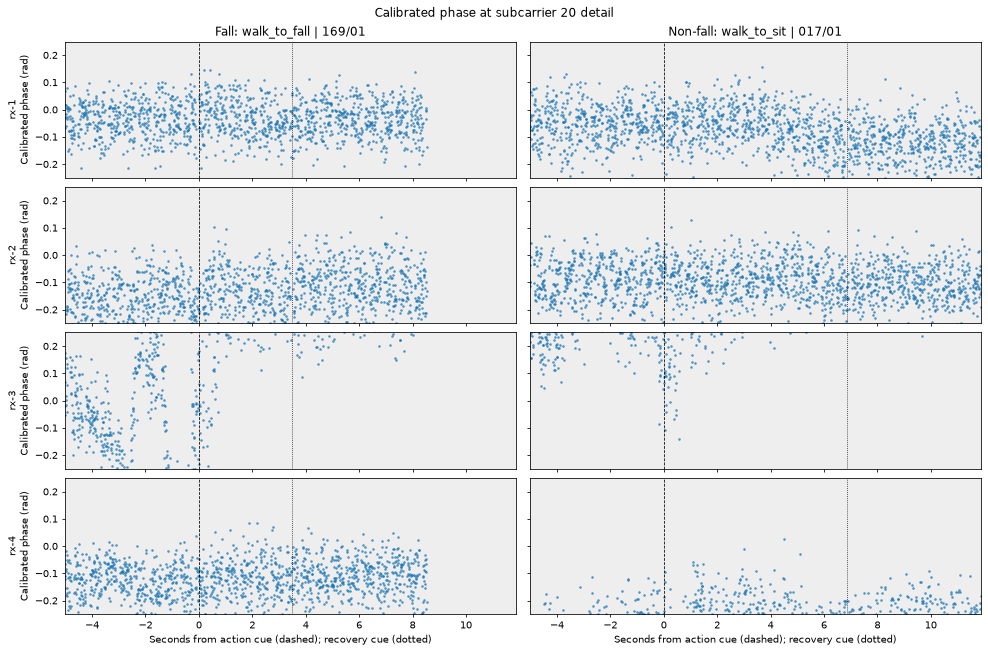

In [26]:
plot_receiver_trace(
    "calibrated_phase", f"Calibrated phase at subcarrier {SUBCARRIER} detail",
    "Calibrated phase (rad)", (-CALIBRATED_DETAIL_LIMIT, CALIBRATED_DETAIL_LIMIT),
)

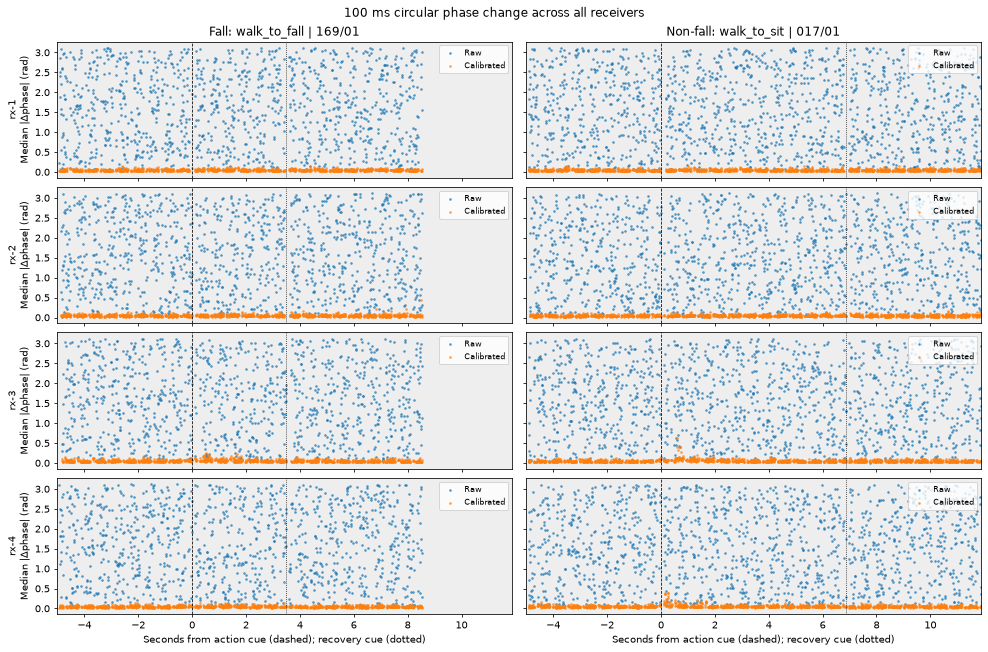

In [27]:
fig, axes = receiver_figure(
    "Median |Δphase| (rad)",
    f"{PHASE_LAG_SECONDS * 1000:g} ms circular phase change across all receivers",
)
for ax, sample in sample_panels(axes):
    for name, label in (("raw_phase_change", "Raw"), ("calibrated_phase_change", "Calibrated")):
        values = np.abs(sample[name])
        enough = np.isfinite(values).sum(axis=1) >= values.shape[1] / 2
        score = np.full(len(sample["time"]), np.nan)
        score[enough] = np.nanmedian(values[enough], axis=1)
        ax.scatter(sample["time"], score, s=3, alpha=0.6, label=label)
    ax.legend(loc="upper right", fontsize=8)
plt.show()

## RSSI and noise floor

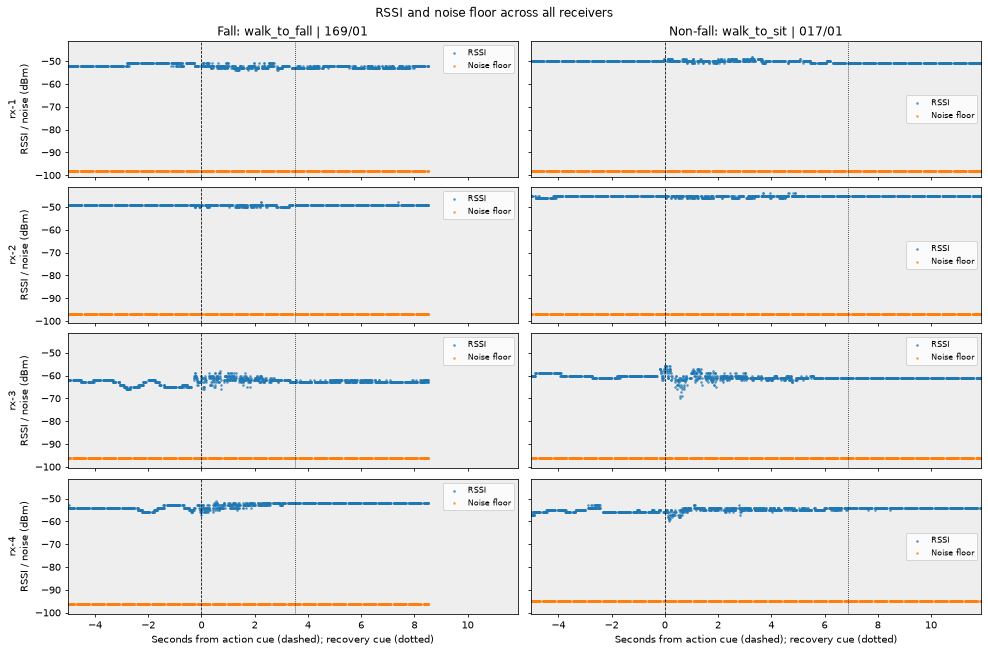

In [28]:
fig, axes = receiver_figure("RSSI / noise (dBm)", "RSSI and noise floor across all receivers")
for ax, sample in sample_panels(axes):
    for name, label in (("rssi", "RSSI"), ("noise_floor", "Noise floor")):
        ax.scatter(
            sample["time"], sample["metadata"][name], s=3, alpha=0.6, label=label,
        )
    ax.legend(loc="best", fontsize=8)
plt.show()

# Capture timing diagnostics

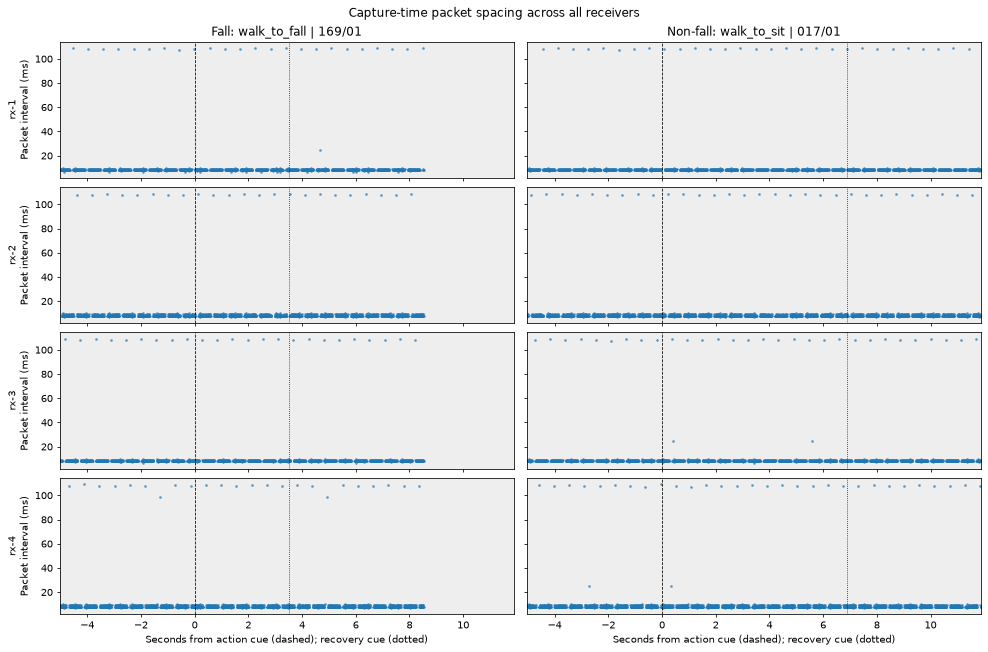

In [29]:
fig, axes = receiver_figure("Packet interval (ms)", "Capture-time packet spacing across all receivers")
for ax, sample in sample_panels(axes):
    t = sample["time"]
    ax.scatter(t[1:], np.diff(t) * 1000, s=3, alpha=0.6)
plt.show()

## Amplitude analysis

### Amplitude variance by subcarrier and activity

In [30]:
AMPLITUDE_VARIANCE_SEED = 42
SCENARIOS_PER_ACTIVITY = 2
rng = np.random.default_rng(AMPLITUDE_VARIANCE_SEED)

variance_candidates = selected_attempts.loc[
    selected_attempts["quality"].ne("bad")
].copy()
variance_candidates["class"] = variance_candidates["activity_label"].map(label_to_class)
required_receivers = set(RECEIVER_IDS)
variance_candidates = variance_candidates.loc[
    variance_candidates["class"].isin(["Fall", "Non-fall"])
    & variance_candidates["receiver_ids"].map(
        lambda ids: required_receivers.issubset(ids)
    )
]
variance_choices = []
for activity, candidates in variance_candidates.groupby("activity_label", sort=True):
    candidates = candidates.sort_values(["scenario_id", "trial_ordinal", "attempt"])
    scenarios = sorted(candidates["scenario_id"].unique())
    if len(scenarios) < SCENARIOS_PER_ACTIVITY:
        raise ValueError(f"{activity} needs {SCENARIOS_PER_ACTIVITY} eligible scenarios.")
    chosen_scenarios = rng.choice(scenarios, size=SCENARIOS_PER_ACTIVITY, replace=False)
    for scenario in chosen_scenarios:
        options = candidates.loc[candidates["scenario_id"].eq(scenario)]
        chosen = options.iloc[int(rng.integers(len(options)))]
        variance_choices.append(chosen)

variance_selection = pd.DataFrame(variance_choices).reset_index(drop=True)
display(variance_selection[[
    "class", "activity_label", "scenario_id", "trial_ordinal", "attempt", "attempt_key",
]])

,class,activity_label,scenario_id,trial_ordinal,attempt,attempt_key
0,Fall,sit_to_fall,sit-to-fall__start_back__end_front,151,1,trials/151_sit-to-fall__start_back__end_front/...
1,Fall,sit_to_fall,sit-to-fall__start_right__end_front,157,1,trials/157_sit-to-fall__start_right__end_front...
2,Non-fall,sit_to_stand,sit-to-stand__start_right__end_back,67,1,trials/067_sit-to-stand__start_right__end_back...
3,Non-fall,sit_to_stand,sit-to-stand__start_back__end_front,91,1,trials/091_sit-to-stand__start_back__end_front...
4,Non-fall,sit_to_walk,sit-to-walk__start_front__end_right,26,1,trials/026_sit-to-walk__start_front__end_right...
5,Non-fall,sit_to_walk,sit-to-walk__start_right__end_right,62,1,trials/062_sit-to-walk__start_right__end_right...
6,Fall,stand_to_fall,stand-to-fall__start_left__end_back,228,1,trials/228_stand-to-fall__start_left__end_back...
7,Fall,stand_to_fall,stand-to-fall__start_left__end_right,223,1,trials/223_stand-to-fall__start_left__end_righ...
8,Non-fall,stand_to_sit,stand-to-sit__start_front__end_front,20,1,trials/020_stand-to-sit__start_front__end_fron...
9,Non-fall,stand_to_sit,stand-to-sit__start_front__end_right,52,1,trials/052_stand-to-sit__start_front__end_righ...


In [31]:
variance_records = {}
for choice_number, chosen in enumerate(variance_choices, start=1):
    intervals = phases.loc[
        phases["attempt_key"].eq(chosen["attempt_key"])
        & phases["phase"].eq("action")
    ]
    if len(intervals) != 1:
        raise ValueError(f"Incomplete action interval: {chosen['attempt_key']}")
    start = int(intervals.iloc[0]["start_ns"])
    end = int(intervals.iloc[0]["end_ns"])
    if end <= start:
        raise ValueError("Action duration must be positive.")
    for receiver_id in RECEIVER_IDS:
        # Decode only this action interval, using the canonical CSI masks.
        recording = session.read_packets(filters=[
            ("attempt_key", "==", chosen["attempt_key"]),
            ("receiver_id", "==", receiver_id),
            ("is_sensing", "==", True),
            ("capture_time_ns", ">=", start),
            ("capture_time_ns", "<", end),
        ])
        signal = phase_signal_from_packets(recording)
        if signal.skipped_layout_rows:
            raise ValueError("CSI layout is not supported for this analysis.")
        if len(recording) != len(signal.time_seconds):
            raise ValueError("Metadata and CSI are not aligned.")
        # Retain the original analysis range, excluding the final two tones.
        amplitude = np.abs(signal.complex_csi[:, :-2])
        valid = (
            np.isfinite(signal.raw_phase[:, :-2])
            & recording["driver_valid"].to_numpy(dtype=bool)[:, None]
        )
        amplitude[~valid] = np.nan
        count = np.isfinite(amplitude).sum(axis=0)
        variance = np.full(amplitude.shape[1], np.nan)
        enough = count >= 2
        variance[enough] = np.nanvar(amplitude[:, enough], axis=0, ddof=1)
        variance_records[chosen["attempt_key"], receiver_id] = {
            "class": chosen["class"], "activity": chosen["activity_label"],
            "scenario": chosen["scenario_id"], "attempt_key": chosen["attempt_key"],
            "attempt_id": signal.attempt_id, "receiver": receiver_id,
            "subcarrier": signal.subcarriers[:-2].copy(),
            "variance": variance, "valid_count": count,
        }
    if choice_number % 4 == 0 or choice_number == len(variance_choices):
        print(f"Analyzed: {choice_number}/{len(variance_choices)} attempts")

amplitude_variance = pd.DataFrame([
    {
        "class": record["class"], "activity": record["activity"],
        "scenario": record["scenario"], "attempt_key": record["attempt_key"],
        "receiver": record["receiver"], "subcarrier": int(tone),
        "variance": float(value), "valid_count": int(count),
    }
    for record in variance_records.values()
    for tone, value, count in zip(
        record["subcarrier"], record["variance"], record["valid_count"], strict=True
    )
])

Analyzed: 4/18 attempts
Analyzed: 8/18 attempts
Analyzed: 12/18 attempts
Analyzed: 16/18 attempts
Analyzed: 18/18 attempts


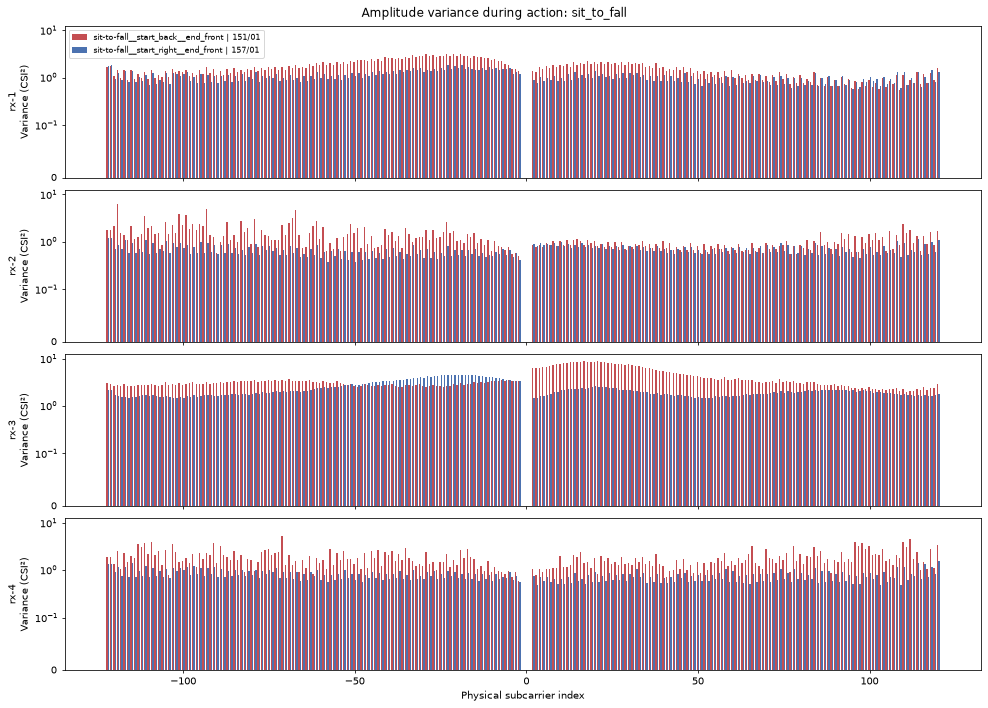

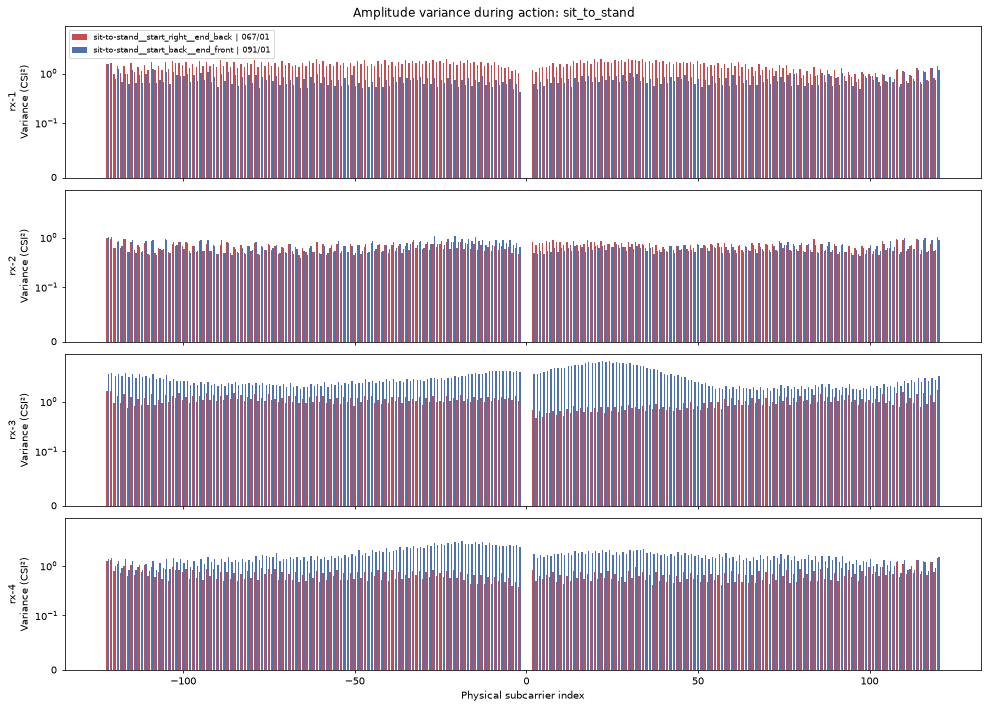

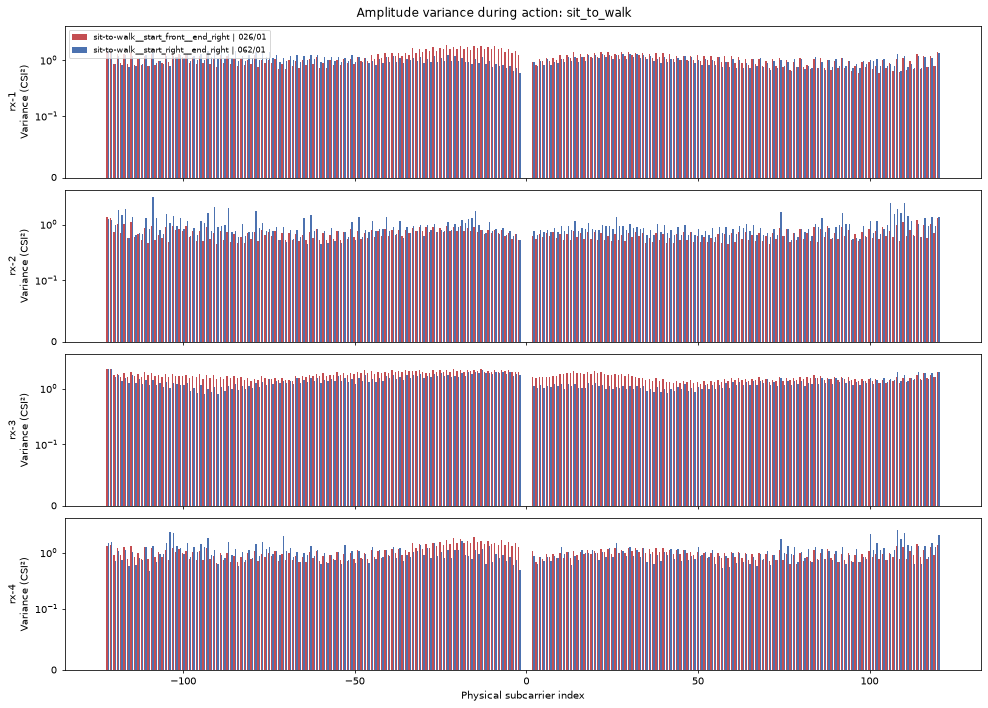

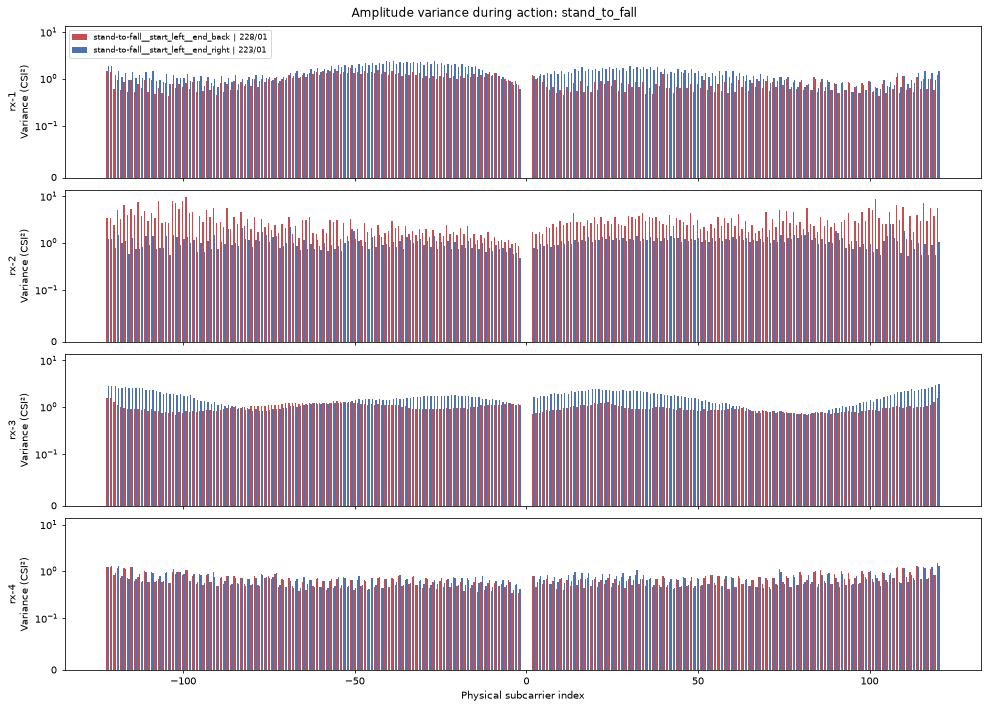

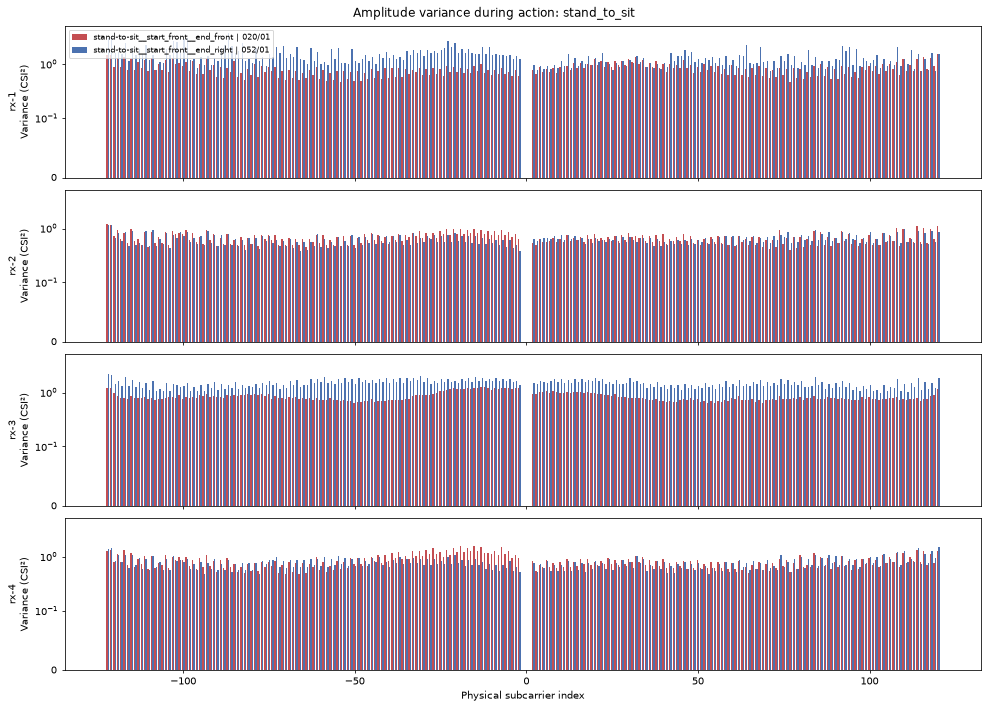

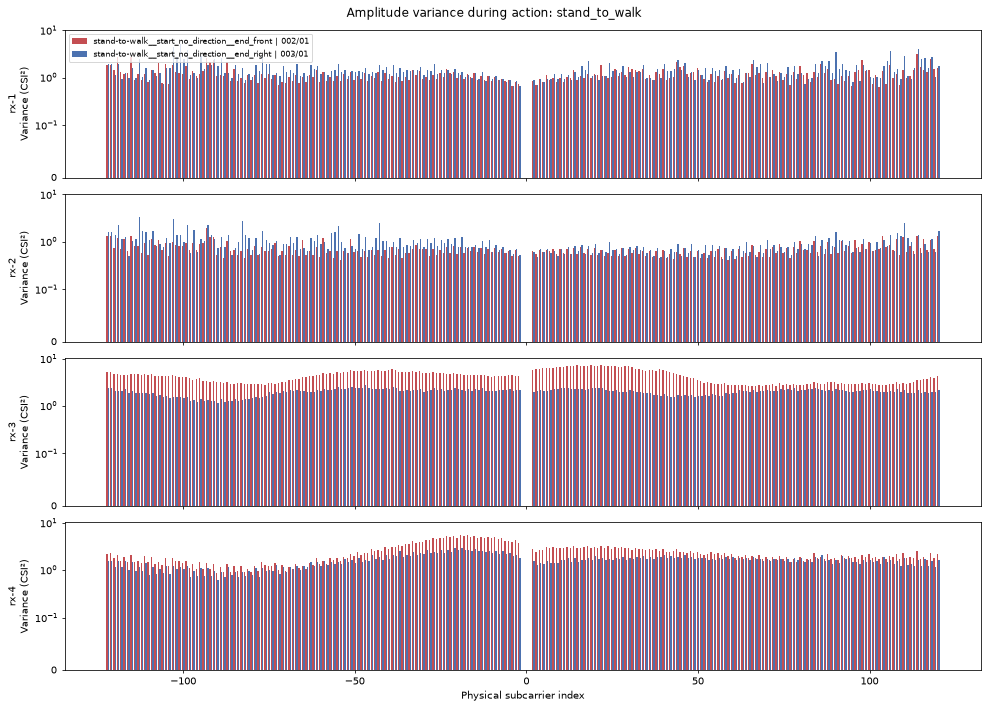

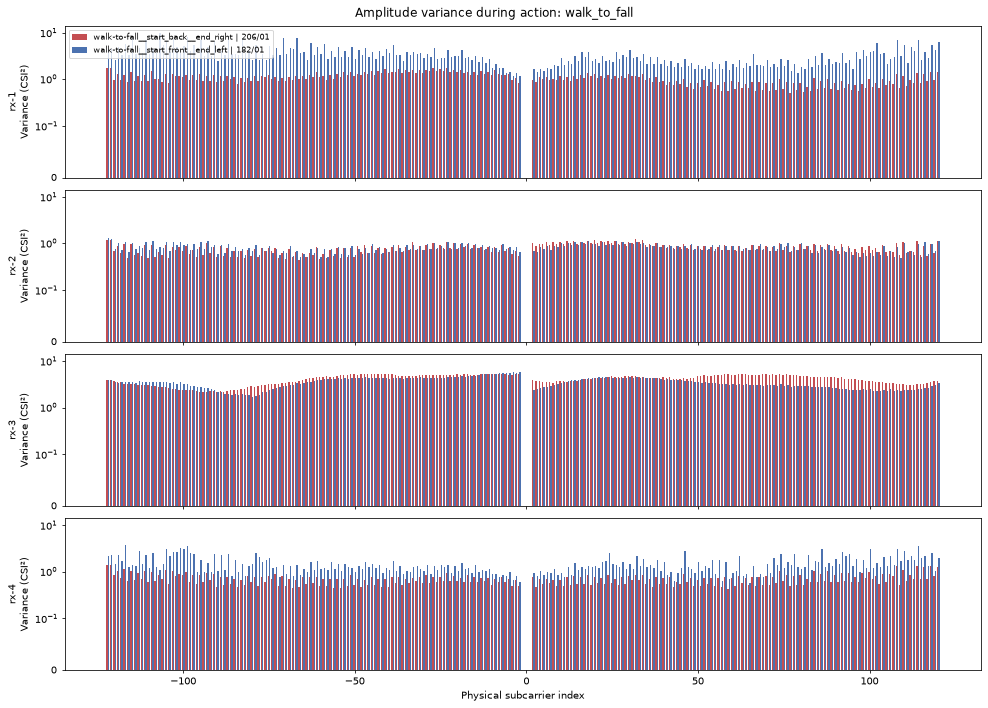

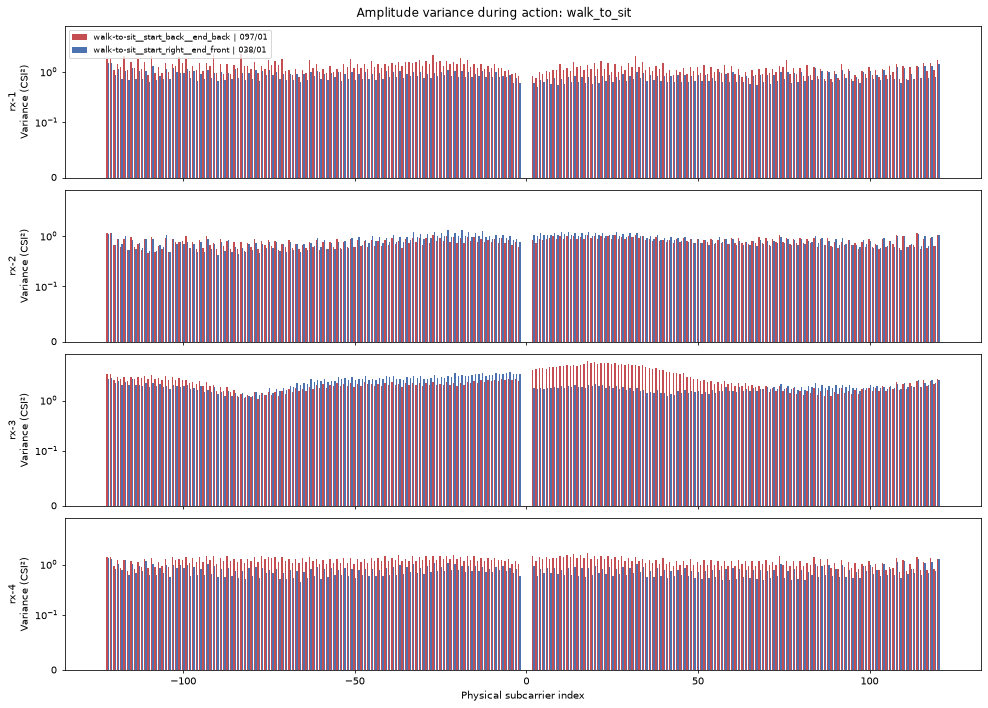

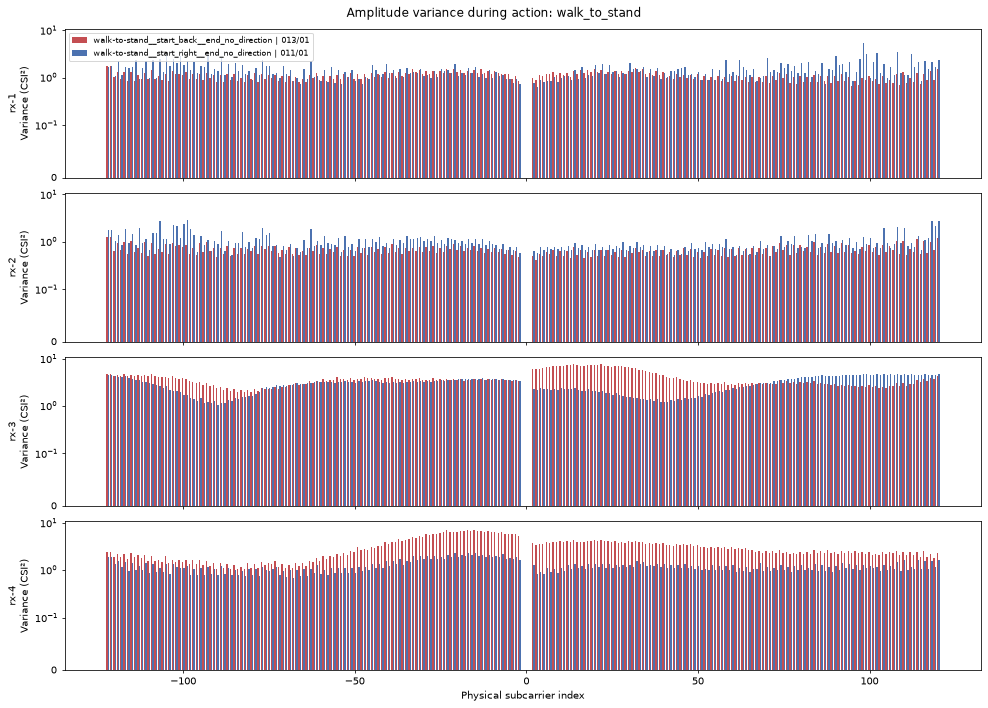

In [32]:
scenario_colors = ("#c44e52", "#4c72b0")
for activity in sorted(variance_selection["activity_label"].unique()):
    selected_rows = variance_selection.loc[
        variance_selection["activity_label"].eq(activity)
    ]
    fig, axes = plt.subplots(
        len(RECEIVER_IDS), 1, squeeze=False, sharex=True, sharey=True,
        figsize=(14, 2.5 * len(RECEIVER_IDS)), layout="constrained",
    )
    for row_index, receiver_id in enumerate(RECEIVER_IDS):
        ax = axes[row_index, 0]
        for color, offset, (_, chosen) in zip(
            scenario_colors, (-0.2, 0.2), selected_rows.iterrows(), strict=True
        ):
            record = variance_records[chosen["attempt_key"], receiver_id]
            ax.bar(
                record["subcarrier"] + offset, record["variance"], color=color,
                width=0.4, label=f"{record['scenario']} | {record['attempt_id']}",
            )
        ax.set_yscale("symlog", linthresh=0.1)
        ax.set_ylabel(f"{receiver_id}\nVariance (CSI²)")
        if row_index == 0:
            ax.legend(fontsize=8, loc="upper left")
    axes[-1, 0].set_xlabel("Physical subcarrier index")
    fig.suptitle(f"Amplitude variance during action: {activity}")
    plt.show()
